# MVP · O CVSS é um bom critério para priorizar a correção de vulnerabilidades?
**UnB · Engenharia de Produção · Prof. André Luiz Marques Serrano · Daniel de Carvalho Vianna (231013322)**

Este notebook executa **todo** o pipeline: coleta (NVD API 2.0 + CISA KEV) → ETL em PySpark (bronze → silver → gold) → gravação no **BigQuery Sandbox** → qualidade (6 dimensões) → análise P1–P5 → gráficos PNG → geração automática de `README.md`, `catalogo_dados.md`, `short_paper.tex`, `LICENSE` e um `.zip`.

**Como rodar:** `Ambiente de execução → Executar tudo` (Ctrl+F9). Única interação humana: a janela de autenticação Google da **Célula 2** (logo no início). Depois deixe a aba aberta: a coleta sem chave da NVD leva em torno de 1 hora (limite de 5 requisições/30 s). A coleta é **retomável**: se o Colab desconectar sem reiniciar o ambiente, basta executar tudo de novo.

Pré-requisito único: ter aberto uma vez https://console.cloud.google.com/bigquery com a conta Google (isso cria o projeto do Sandbox, gratuito e sem cartão).

In [4]:
# ═══ CÉLULA 1 · Configuração ═══
import os, sys, json, time, glob, shutil, datetime, subprocess, re, math, textwrap, random, csv
import urllib.request, urllib.parse, urllib.error

MODO_TESTE = os.environ.get("MVP_TESTE") == "1"
PROJECT_ID = os.environ.get("MVP_PROJECT_ID", "")
BQ_DATASET = "mvp_cve"
BQ_LOCATION = "US"

WORK = os.environ.get("MVP_WORK") or ("/content/mvp" if os.path.isdir("/content") else os.path.abspath("./mvp_work"))
RAW, WH, PQ, SAIDA = (f"{WORK}/{p}" for p in ("raw", "warehouse", "parquet", "saida"))
for _d in (f"{RAW}/nvd", f"{RAW}/kev", WH, PQ, SAIDA):
    os.makedirs(_d, exist_ok=True)

INICIO, FIM = datetime.date(2021, 1, 1), datetime.date(2025, 12, 31)   # recorte por data de publicação
JANELA_DIAS = 120            # máximo permitido pela NVD para pubStartDate/pubEndDate
RESULTADOS_POR_PAGINA = 500
PAUSA_S = 6.5                # 5 requisições / 30 s sem chave de API
NVD_URL = "https://services.nvd.nist.gov/rest/json/cves/2.0"
KEV_URL = "https://www.cisa.gov/sites/default/files/csv/known_exploited_vulnerabilities.csv"
UA = {"User-Agent": "mvp-unb-cve/1.0 (trabalho academico UnB)"}
NOTEBOOK = "MVP_CVSS_KEV.ipynb"

# Critério explícito do veredito da hipótese (definido ANTES de ver os resultados)
LIM_PRECISAO = 10.0    # C1: % das CVEs críticas/altas que constam no KEV < 10%  -> backlog grande e pouco eficiente
LIM_COBERTURA = 90.0   # C2: % do KEV coberto por críticas/altas < 90%          -> parcela relevante (>=10%) do KEV fica de fora
print("Modo:", "TESTE (dados sintéticos)" if MODO_TESTE else "PRODUÇÃO", "| pasta de trabalho:", WORK)

Modo: PRODUÇÃO | pasta de trabalho: /content/mvp


## Célula 2 · Autenticação Google e projeto do BigQuery

In [5]:
# ═══ CÉLULA 2 · Autenticação + projeto + dataset no BigQuery ═══
BQ = {}
if MODO_TESTE:
    print("MODO_TESTE: autenticação e BigQuery ignorados.")
else:
    from google.colab import auth
    auth.authenticate_user()
    import google.auth
    from google.cloud import bigquery

    creds, proj_default = google.auth.default()

    def _gcloud(args):
        return subprocess.run(["gcloud"] + args, capture_output=True, text=True)

    proj = PROJECT_ID or proj_default
    if not proj:
        r = _gcloud(["projects", "list", "--filter=lifecycleState:ACTIVE", "--format=value(projectId)"])
        ids = [l.strip() for l in r.stdout.splitlines() if l.strip()]
        if ids:
            proj = ids[0]
            print("Projetos encontrados:", ids, "-> usando", proj, "(para outro, defina PROJECT_ID na Célula 1)")
        else:
            novo = "mvp-cve-unb-" + "".join(random.choices("0123456789abcdef", k=6))
            r = _gcloud(["projects", "create", novo])
            if r.returncode == 0:
                proj = novo
                print("Projeto criado:", proj)
    if not proj:
        raise RuntimeError(
            "Não encontrei nem consegui criar um projeto Google Cloud.\n"
            "1) Abra https://console.cloud.google.com/bigquery com a MESMA conta do Colab e aceite os termos (modo Sandbox);\n"
            "2) copie o ID do projeto que aparece no topo da página;\n"
            "3) cole-o em PROJECT_ID na Célula 1 e execute tudo de novo.")
    client = bigquery.Client(project=proj, credentials=creds)
    ds = bigquery.Dataset(f"{proj}.{BQ_DATASET}")
    ds.location = BQ_LOCATION
    client.create_dataset(ds, exists_ok=True)
    list(client.query("SELECT 1").result())      # teste de permissão/faturamento
    BQ = {"client": client, "projeto": proj}
    print(f"BigQuery OK · projeto={proj} · dataset={BQ_DATASET} · local={BQ_LOCATION}")

Projetos encontrados: ['boreal-depth-426022-u4'] -> usando boreal-depth-426022-u4 (para outro, defina PROJECT_ID na Célula 1)
BigQuery OK · projeto=boreal-depth-426022-u4 · dataset=mvp_cve · local=US


## Célula 3 · Dependências (PySpark local) e Java

In [6]:
# ═══ CÉLULA 3 · Dependências ═══
if not MODO_TESTE:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyspark==3.5.3"])
    if shutil.which("java") is None:
        subprocess.check_call("apt-get -qq update && apt-get -qq install -y openjdk-17-jre-headless", shell=True)
import pandas as pd
import matplotlib
matplotlib.use("Agg") if MODO_TESTE else None
import matplotlib.pyplot as plt
print(subprocess.run("java -version 2>&1 | head -1", shell=True, capture_output=True, text=True).stdout.strip())

[0.010s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


## Célula 4 · Coleta (NVD API 2.0 em janelas de 120 dias + CISA KEV)
Retry com *backoff* exponencial, validação do JSON, gravação atômica e retomada (arquivos já baixados são pulados). Ao final, auditoria: para cada janela compara-se o total anunciado pela API com o número de CVEs efetivamente gravadas.

In [7]:
# ═══ CÉLULA 4 · Coleta ═══
def get(url, tries=6, timeout=180, json_obrigatorio=True):
    ultimo = None
    for i in range(tries):
        try:
            req = urllib.request.Request(url, headers=UA)
            with urllib.request.urlopen(req, timeout=timeout) as r:
                data = r.read()
            if json_obrigatorio:
                d = json.loads(data)
                if "vulnerabilities" not in d:
                    raise ValueError("resposta sem 'vulnerabilities': " + str(d)[:200])
            return data
        except urllib.error.HTTPError as e:
            ultimo = e
            if e.code == 404:
                raise
            espera = min(30 * 2 ** i, 300) if e.code in (403, 429, 503) else 10 * 2 ** i
        except Exception as e:                       # IncompleteRead, timeout, JSON truncado...
            ultimo = e
            espera = 10 * 2 ** i
        print(f"  tentativa {i+1}/{tries} falhou ({type(ultimo).__name__}: {str(ultimo)[:120]}); aguardando {espera}s")
        time.sleep(espera)
    raise RuntimeError(f"Falha ao baixar {url}: {ultimo}")

def janelas():
    out, ini = [], INICIO
    while ini <= FIM:
        fim = min(ini + datetime.timedelta(days=JANELA_DIAS - 1), FIM)
        out.append((ini, fim)); ini = fim + datetime.timedelta(days=1)
    return out

def coletar_janela(ini, fim):
    tag, start, total = ini.strftime("%Y%m%d"), 0, None
    while total is None or start < total:
        path = f"{RAW}/nvd/nvd_{tag}_{start:06d}.json"
        d = None
        if os.path.exists(path):
            try:
                d = json.load(open(path, encoding="utf-8"))
            except Exception:
                os.remove(path); d = None          # arquivo corrompido: baixa de novo
        if d is None:
            q = urllib.parse.urlencode({"pubStartDate": ini.strftime("%Y-%m-%dT00:00:00.000"),
                                        "pubEndDate": fim.strftime("%Y-%m-%dT23:59:59.999"),
                                        "resultsPerPage": RESULTADOS_POR_PAGINA, "startIndex": start})
            data = get(f"{NVD_URL}?{q}")
            with open(path + ".part", "wb") as f:
                f.write(data)
            os.replace(path + ".part", path)
            d = json.loads(data)
            print(f"  NVD {tag} {start + len(d['vulnerabilities'])}/{d['totalResults']}")
            time.sleep(PAUSA_S)
        total = d["totalResults"]
        n = len(d["vulnerabilities"])
        if n == 0:
            break
        start += n

def coletar_kev():
    path = f"{RAW}/kev/kev.csv"
    if not os.path.exists(path):
        data = get(KEV_URL, json_obrigatorio=False)
        with open(path + ".part", "wb") as f:
            f.write(data)
        os.replace(path + ".part", path)
    return path

def auditar_raw():
    jan, mt = {}, []
    for p in sorted(glob.glob(f"{RAW}/nvd/nvd_*.json")) + [f"{RAW}/kev/kev.csv"]:
        mt.append(os.path.getmtime(p))
        if p.endswith(".csv"):
            continue
        tag = os.path.basename(p).split("_")[1]
        d = json.load(open(p, encoding="utf-8"))
        j = jan.setdefault(tag, {"total": d["totalResults"], "baixadas": 0, "arquivos": 0})
        j["baixadas"] += len(d["vulnerabilities"]); j["arquivos"] += 1
    esperadas = [i.strftime("%Y%m%d") for i, _ in janelas()]
    faltando = [t for t in esperadas if t not in jan]
    incompletas = [t for t, j in jan.items() if j["baixadas"] != j["total"]]
    nvd_bytes = sum(os.path.getsize(p) for p in glob.glob(f"{RAW}/nvd/nvd_*.json"))
    with open(f"{RAW}/kev/kev.csv", encoding="utf-8", newline="") as f:
        kev_linhas = sum(1 for _ in csv.DictReader(f))
    utc = datetime.timezone.utc
    return {
        "coleta_inicio_utc": datetime.datetime.fromtimestamp(min(mt), utc).strftime("%Y-%m-%d %H:%M:%S"),
        "coleta_fim_utc": datetime.datetime.fromtimestamp(max(mt), utc).strftime("%Y-%m-%d %H:%M:%S"),
        "recorte_publicacao": f"{INICIO} a {FIM}",
        "n_janelas": len(esperadas), "janela_dias": JANELA_DIAS, "resultados_por_pagina": RESULTADOS_POR_PAGINA,
        "n_arquivos_nvd": len(glob.glob(f"{RAW}/nvd/nvd_*.json")),
        "mb_nvd": round(nvd_bytes / 1e6, 1),
        "nvd_cves_baixadas": sum(j["baixadas"] for j in jan.values()),
        "nvd_total_anunciado_api": sum(j["total"] for j in jan.values()),
        "janelas_faltando": faltando, "janelas_incompletas": incompletas,
        "kev_linhas": kev_linhas, "kev_bytes": os.path.getsize(f"{RAW}/kev/kev.csv"),
        "formato_nvd": f"JSON (API 2.0, janelas de {JANELA_DIAS} dias, {RESULTADOS_POR_PAGINA} CVEs/página)",
        "formato_kev": "CSV",
        "chave_api_nvd": "não utilizada",
    }

if not MODO_TESTE:
    for _i, (_a, _b) in enumerate(janelas(), 1):
        print(f"Janela {_i}/{len(janelas())}: {_a} a {_b}")
        coletar_janela(_a, _b)
    coletar_kev()
META = auditar_raw()
if META["janelas_faltando"] or META["janelas_incompletas"]:
    raise RuntimeError(f"Coleta incompleta: faltando={META['janelas_faltando']} incompletas={META['janelas_incompletas']}. Execute novamente (retoma de onde parou).")
json.dump(META, open(f"{SAIDA}/coleta_meta.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
print(json.dumps(META, indent=2, ensure_ascii=False))

Janela 1/16: 2021-01-01 a 2021-04-30
  NVD 20210101 500/6960
  NVD 20210101 1000/6960
  NVD 20210101 1500/6960
  NVD 20210101 2000/6960
  NVD 20210101 2500/6960
  NVD 20210101 3000/6960
  NVD 20210101 3500/6960
  NVD 20210101 4000/6960
  NVD 20210101 4500/6960
  NVD 20210101 5000/6960
  NVD 20210101 5500/6960
  NVD 20210101 6000/6960
  NVD 20210101 6500/6960
  NVD 20210101 6960/6960
Janela 2/16: 2021-05-01 a 2021-08-28
  NVD 20210501 500/7139
  NVD 20210501 1000/7139
  NVD 20210501 1500/7139
  NVD 20210501 2000/7139
  NVD 20210501 2500/7139
  NVD 20210501 3000/7139
  NVD 20210501 3500/7139
  NVD 20210501 4000/7139
  NVD 20210501 4500/7139
  NVD 20210501 5000/7139
  NVD 20210501 5500/7139
  NVD 20210501 6000/7139
  NVD 20210501 6500/7139
  NVD 20210501 7000/7139
  NVD 20210501 7139/7139
Janela 3/16: 2021-08-29 a 2021-12-26
  NVD 20210829 500/7650
  NVD 20210829 1000/7650
  NVD 20210829 1500/7650
  NVD 20210829 2000/7650
  NVD 20210829 2500/7650
  NVD 20210829 3000/7650
  NVD 20210829 35

## Célula 5 · Spark local + camada bronze (dados como chegaram)

In [8]:
# ═══ CÉLULA 5 · Spark e bronze ═══
from pyspark.sql import SparkSession, functions as F, Window
from pyspark import StorageLevel

spark = (SparkSession.builder.master("local[*]").appName("mvp_cve")
         .config("spark.driver.memory", os.environ.get("MVP_MEM", "7g"))
         .config("spark.sql.shuffle.partitions", "16")
         .config("spark.sql.ansi.enabled", "true")          # mesmo comportamento do ambiente em que o ETL foi desenvolvido
         .config("spark.sql.caseSensitive", "true")
         .config("spark.sql.warehouse.dir", WH)
         .config("spark.sql.parquet.outputTimestampType", "TIMESTAMP_MICROS")
         .config("spark.ui.enabled", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
S = "mvp_cve"
spark.sql(f"DROP DATABASE IF EXISTS {S} CASCADE")
spark.sql(f"CREATE DATABASE {S}")

def sql(q):                                   # usa @S no lugar do schema (evita problemas de chaves em f-strings)
    return spark.sql(q.replace("@S", S))

def to_pd(df):
    return pd.DataFrame([tuple(r) for r in df.collect()], columns=df.columns)

bronze_nvd = (spark.read.option("multiLine", True).json(f"{RAW}/nvd/nvd_*.json")
              .select(F.explode("vulnerabilities").alias("v")).select("v.cve.*"))
bronze_nvd.write.mode("overwrite").saveAsTable(f"{S}.bronze_nvd")

bronze_kev = (spark.read.option("header", True).option("multiLine", True).option("escape", "\"")
              .csv(f"{RAW}/kev/kev.csv"))
bronze_kev = bronze_kev.toDF(*[c.replace("﻿", "").strip() for c in bronze_kev.columns])
bronze_kev.write.mode("overwrite").saveAsTable(f"{S}.bronze_kev")
N_BRONZE_NVD = spark.table(f"{S}.bronze_nvd").count()
N_BRONZE_KEV = spark.table(f"{S}.bronze_kev").count()
print("bronze_nvd:", N_BRONZE_NVD, "| bronze_kev:", N_BRONZE_KEV)

bronze_nvd: 170006 | bronze_kev: 1769


## Célula 6 · Silver (limpeza, tipagem, regras de negócio)

In [9]:
# ═══ CÉLULA 6 · Silver ═══
b = spark.table(f"{S}.bronze_nvd")
_metric_fields = {f.name for f in b.schema["metrics"].dataType.fields}

def _metrica(ver):
    """Métrica CVSS v3.x: entrada 'Primary' (NVD) se existir; senão a primeira listada."""
    n = f"metrics.cvssMetricV{ver}"
    if f"cvssMetricV{ver}" not in _metric_fields:
        return None
    return f"coalesce(try_element_at(filter({n}, x -> x.type = 'Primary'), 1), try_element_at({n}, 1))"

def _cvss(campo):
    # regra 1: v3.1; se ausente, v3.0 (se ambas ausentes -> NULL, depois SEM_CVSS)
    partes = [F.expr(f"{m}.cvssData.{campo}") for m in (_metrica("31"), _metrica("30")) if m]
    return F.coalesce(*partes) if partes else F.lit(None).cast("string")

_cpes = ("flatten(transform(configurations, c -> flatten(transform(c.nodes, n -> "
         "coalesce(transform(filter(n.cpeMatch, m -> m.vulnerable = true), m -> m.criteria), cast(array() as array<string>))))))")

silver = b.select(
    F.upper(F.trim("id")).alias("cve_id"),
    F.to_timestamp("published").alias("publicado_em"),
    F.to_timestamp("lastModified").alias("modificado_em"),
    F.col("vulnStatus").alias("status_nvd"),
    F.expr("try_element_at(filter(descriptions, d -> d.lang = 'en'), 1).value").alias("descricao"),
    _cvss("baseScore").cast("double").alias("cvss_score"),
    _cvss("baseSeverity").alias("cvss_severidade"),
    _cvss("vectorString").alias("cvss_vetor"),
    _cvss("attackVector").alias("vetor_ataque"),
    F.expr("try_element_at(flatten(transform(weaknesses, w -> transform(w.description, d -> d.value))), 1)").alias("cwe_id"),
    F.expr(_cpes).alias("_cpes"),
)
silver = (silver
          .withColumn("cvss_severidade", F.coalesce(F.upper("cvss_severidade"), F.lit("SEM_CVSS")))
          .withColumn("cwe_id", F.coalesce("cwe_id", F.lit("SEM_CWE"))))

# recorte temporal por data de publicação (regra 9)
silver = silver.filter((F.col("publicado_em") >= F.lit(f"{INICIO} 00:00:00").cast("timestamp")) &
                       (F.col("publicado_em") < F.lit(f"{FIM + datetime.timedelta(days=1)} 00:00:00").cast("timestamp")))
# deduplicação (regra 6): 1 linha por cve_id, a de maior lastModified
w = Window.partitionBy("cve_id").orderBy(F.col("modificado_em").desc())
silver = silver.withColumn("_rn", F.row_number().over(w)).filter("_rn = 1").drop("_rn")
silver = silver.persist(StorageLevel.MEMORY_AND_DISK)

ponte = (silver.select("cve_id", F.explode_outer("_cpes").alias("cpe"))
         .withColumn("vendor", F.lower(F.expr("try_element_at(split(cpe, ':'), 4)")))
         .filter("vendor IS NOT NULL AND vendor NOT IN ('*', '-', '')")
         .select("cve_id", "vendor").distinct())
ponte.write.mode("overwrite").saveAsTable(f"{S}.silver_cve_vendor")
silver.drop("_cpes").write.mode("overwrite").saveAsTable(f"{S}.silver_cve")
silver.unpersist()

kev = (spark.table(f"{S}.bronze_kev")
       .select(F.upper(F.trim("cveID")).alias("cve_id"),
               F.col("vendorProject").alias("vendor_kev"), F.col("product").alias("produto_kev"),
               F.to_date("dateAdded").alias("kev_incluido_em"),
               F.to_date("dueDate").alias("kev_prazo"),
               F.col("knownRansomwareCampaignUse").alias("uso_ransomware")))
wk = Window.partitionBy("cve_id").orderBy(F.col("kev_incluido_em").asc())
kev = kev.withColumn("_rn", F.row_number().over(wk)).filter("_rn = 1").drop("_rn")
kev.write.mode("overwrite").saveAsTable(f"{S}.silver_kev")
print("silver_cve:", spark.table(f"{S}.silver_cve").count(), "| silver_cve_vendor:", spark.table(f"{S}.silver_cve_vendor").count(),
      "| silver_kev:", spark.table(f"{S}.silver_kev").count())

silver_cve: 170006 | silver_cve_vendor: 148013 | silver_kev: 1769


## Célula 7 · Gold (modelo estrela)
`fato_cve` (grão: 1 CVE) · `dim_data` · `dim_cwe` · `ponte_cve_vendor` (muitos-para-muitos)

In [10]:
# ═══ CÉLULA 7 · Gold ═══
CWE_NOMES = {
    "CWE-20": "Validação de entrada imprópria", "CWE-22": "Path traversal", "CWE-59": "Resolução imprópria de links",
    "CWE-73": "Controle externo de nome/caminho de arquivo", "CWE-74": "Injeção", "CWE-77": "Injeção de comando",
    "CWE-78": "Injeção de comando de SO", "CWE-79": "Cross-site scripting (XSS)", "CWE-89": "Injeção de SQL",
    "CWE-94": "Injeção de código", "CWE-119": "Limites de buffer em memória", "CWE-120": "Cópia de buffer sem checar tamanho",
    "CWE-121": "Buffer overflow na pilha", "CWE-122": "Buffer overflow no heap", "CWE-125": "Leitura fora dos limites",
    "CWE-190": "Overflow de inteiro", "CWE-200": "Exposição de informação sensível", "CWE-259": "Senha embutida no código",
    "CWE-269": "Gestão imprópria de privilégios", "CWE-276": "Permissões padrão incorretas", "CWE-284": "Controle de acesso impróprio",
    "CWE-287": "Autenticação imprópria", "CWE-306": "Falta de autenticação em função crítica", "CWE-346": "Erro de validação de origem",
    "CWE-352": "Cross-site request forgery (CSRF)", "CWE-400": "Consumo descontrolado de recursos", "CWE-416": "Use-after-free",
    "CWE-427": "Caminho de busca não controlado", "CWE-434": "Upload de arquivo perigoso irrestrito", "CWE-476": "Dereferência de ponteiro nulo",
    "CWE-502": "Desserialização de dados não confiáveis", "CWE-611": "Referência a entidade externa XML (XXE)",
    "CWE-668": "Exposição de recurso à esfera errada", "CWE-787": "Escrita fora dos limites", "CWE-798": "Credenciais embutidas no código",
    "CWE-862": "Autorização ausente", "CWE-863": "Autorização incorreta", "CWE-917": "Injeção de linguagem de expressão",
    "CWE-918": "Server-side request forgery (SSRF)", "CWE-1321": "Modificação de protótipo de objeto",
}
s = spark.table(f"{S}.silver_cve"); k = spark.table(f"{S}.silver_kev")

fato = (s.join(k.select("cve_id", "kev_incluido_em", "uso_ransomware"), "cve_id", "left")
        .withColumn("data_publicacao", F.to_date("publicado_em"))
        .withColumn("sk_data_publicacao", F.date_format("data_publicacao", "yyyyMMdd").cast("int"))
        .withColumn("flag_kev", F.col("kev_incluido_em").isNotNull())
        .withColumn("dias_ate_kev", F.datediff("kev_incluido_em", "data_publicacao"))
        .select("cve_id", "sk_data_publicacao", "cvss_score", "cvss_severidade", "vetor_ataque",
                "cwe_id", "status_nvd", "flag_kev", "kev_incluido_em", "dias_ate_kev", "uso_ransomware", "modificado_em"))
fato.write.mode("overwrite").saveAsTable(f"{S}.fato_cve")

_dias = ["domingo", "segunda-feira", "terça-feira", "quarta-feira", "quinta-feira", "sexta-feira", "sábado"]
datas = (spark.sql(f"SELECT explode(sequence(to_date('{INICIO}'), to_date('{FIM}'), interval 1 day)) AS data")
         .select(F.date_format("data", "yyyyMMdd").cast("int").alias("sk_data"), "data",
                 F.year("data").alias("ano"), F.quarter("data").alias("trimestre"), F.month("data").alias("mes"),
                 F.element_at(F.array(*[F.lit(x) for x in _dias]), F.dayofweek("data")).alias("dia_semana")))
datas.write.mode("overwrite").saveAsTable(f"{S}.dim_data")

nomes = spark.createDataFrame(list(CWE_NOMES.items()), ["cwe_id", "nome"])
dim_cwe = (s.select("cwe_id").distinct().join(nomes, "cwe_id", "left")
           .withColumn("tipo", F.when(F.col("cwe_id").rlike("^CWE-[0-9]+$"), "CWE específico")
                                .when(F.col("cwe_id") == "SEM_CWE", "Sem informação")
                                .otherwise("Categoria especial NVD")))
dim_cwe.write.mode("overwrite").saveAsTable(f"{S}.dim_cwe")
spark.table(f"{S}.silver_cve_vendor").write.mode("overwrite").saveAsTable(f"{S}.ponte_cve_vendor")

TABELAS = [("bronze_nvd", "bronze"), ("bronze_kev", "bronze"), ("silver_cve", "silver"), ("silver_kev", "silver"),
           ("fato_cve", "gold"), ("dim_data", "gold"), ("dim_cwe", "gold"), ("ponte_cve_vendor", "gold")]
for t, cam in TABELAS:
    print(f"{cam:7s} {t:18s} {spark.table(f'{S}.{t}').count():>10,}")

bronze  bronze_nvd            170,006
bronze  bronze_kev              1,769
silver  silver_cve            170,006
silver  silver_kev              1,769
gold    fato_cve              170,006
gold    dim_data                1,826
gold    dim_cwe                   705
gold    ponte_cve_vendor      148,013


## Célula 8 · Persistência na nuvem (BigQuery) e prova de gravação
Silver e gold são exportadas do Spark em Parquet e carregadas no BigQuery (*load job*, permitido no Sandbox). Em seguida confere-se, com `SELECT COUNT(*)` no próprio BigQuery, se a contagem de linhas bate com a do Spark. Se não bater, o notebook para.

In [11]:
# ═══ CÉLULA 8 · BigQuery ═══
TABELAS_BQ = ["silver_cve", "silver_kev", "fato_cve", "dim_data", "dim_cwe", "ponte_cve_vendor"]
CAMADA = dict((t, c) for t, c in TABELAS)
PERSIST = []
for t in TABELAS_BQ:
    df = spark.table(f"{S}.{t}")
    n_spark = df.count()
    pdir = f"{PQ}/{t}"
    shutil.rmtree(pdir, ignore_errors=True)
    df.coalesce(1).write.mode("overwrite").parquet(pdir)
    parte = glob.glob(f"{pdir}/part-*.parquet")[0]
    if MODO_TESTE:
        PERSIST.append({"tabela": t, "camada": CAMADA[t], "linhas_spark": n_spark, "linhas_nuvem": n_spark,
                        "mb": round(os.path.getsize(parte) / 1e6, 2)})
        continue
    client, proj = BQ["client"], BQ["projeto"]
    tid = f"{proj}.{BQ_DATASET}.{t}"
    cfg = bigquery.LoadJobConfig(source_format=bigquery.SourceFormat.PARQUET,
                                 write_disposition=bigquery.WriteDisposition.WRITE_TRUNCATE)
    with open(parte, "rb") as f:
        client.load_table_from_file(f, tid, job_config=cfg).result()
    n_bq = list(client.query(f"SELECT COUNT(*) AS n FROM `{tid}`").result())[0]["n"]
    tab = client.get_table(tid)
    if n_bq != n_spark:
        raise RuntimeError(f"Contagem divergente em {t}: Spark={n_spark} BigQuery={n_bq}")
    PERSIST.append({"tabela": t, "camada": CAMADA[t], "linhas_spark": n_spark, "linhas_nuvem": int(n_bq),
                    "mb": round((tab.num_bytes or 0) / 1e6, 2)})
    print(f"gravada {tid}: {n_bq:,} linhas")

if MODO_TESTE:
    BQ_URL, BQ_LOCAL = "(modo teste: nada foi enviado ao BigQuery)", "ARMAZENAMENTO LOCAL (MODO TESTE)"
else:
    BQ_LOCAL = f"{BQ['projeto']}.{BQ_DATASET}"
    BQ_URL = (f"https://console.cloud.google.com/bigquery?project={BQ['projeto']}"
              f"&p={BQ['projeto']}&d={BQ_DATASET}&page=dataset")
    print("\nTabelas no BigQuery:", [t.table_id for t in BQ["client"].list_tables(f"{BQ['projeto']}.{BQ_DATASET}")])
print("Console do BigQuery:", BQ_URL)

gravada boreal-depth-426022-u4.mvp_cve.silver_cve: 170,006 linhas
gravada boreal-depth-426022-u4.mvp_cve.silver_kev: 1,769 linhas
gravada boreal-depth-426022-u4.mvp_cve.fato_cve: 170,006 linhas
gravada boreal-depth-426022-u4.mvp_cve.dim_data: 1,826 linhas
gravada boreal-depth-426022-u4.mvp_cve.dim_cwe: 705 linhas
gravada boreal-depth-426022-u4.mvp_cve.ponte_cve_vendor: 148,013 linhas

Tabelas no BigQuery: ['dim_cwe', 'dim_data', 'fato_cve', 'ponte_cve_vendor', 'silver_cve', 'silver_kev']
Console do BigQuery: https://console.cloud.google.com/bigquery?project=boreal-depth-426022-u4&p=boreal-depth-426022-u4&d=mvp_cve&page=dataset


## Célula 9 · Funções auxiliares de formatação e gráficos

In [12]:
# ═══ CÉLULA 9 · Auxiliares ═══
AZUL, LARANJA, CINZA, VERDE = "#1f5fa8", "#d9730d", "#8a8f98", "#2a9d8f"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})

def fmt(x, d=0):
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "n/d"
    return f"{x:,.{d}f}".replace(",", "§").replace(".", ",").replace("§", ".")

def pct(x, d=1):
    return fmt(x, d) + "%"

def fecha(caminho):
    plt.tight_layout()
    plt.savefig(caminho, dpi=150, bbox_inches="tight")
    if not MODO_TESTE:
        plt.show()
    plt.close()

def tabela_png(df, titulo, caminho, larguras, fonte=9, quebra=None):
    quebra = quebra or [40] * len(df.columns)
    cel = [[textwrap.fill(str(v), quebra[j]) for j, v in enumerate(row)] for row in df.values.tolist()]
    linhas_extra = sum(max(c.count("\n") for c in row) for row in cel)
    fig, ax = plt.subplots(figsize=(13, 1.2 + 0.38 * (len(cel) + 1) + 0.2 * linhas_extra))
    ax.axis("off")
    tb = ax.table(cellText=cel, colLabels=list(df.columns), loc="upper center", cellLoc="left", colWidths=larguras)
    tb.auto_set_font_size(False); tb.set_fontsize(fonte)
    for (r, c), cell in tb.get_celld().items():
        cell.set_edgecolor("#c9ccd1")
        if r == 0:
            cell.set_facecolor(AZUL); cell.set_text_props(color="white", fontweight="bold")
        else:
            nl = max(x.count("\n") for x in cel[r - 1]) + 1
            cell.set_height(0.055 * nl + 0.01)
            cell.set_facecolor("#f4f6f9" if r % 2 == 0 else "white")
    ax.set_title(titulo, fontsize=12, fontweight="bold", loc="left")
    fecha(caminho)

def md_tabela(df, alinha=None):
    cab = "| " + " | ".join(df.columns) + " |\n|" + "|".join("---:" if (alinha and alinha[i] == "r") else "---" for i in range(len(df.columns))) + "|\n"
    return cab + "\n".join("| " + " | ".join(str(v) for v in r) + " |" for r in df.values.tolist())

## Célula 10 · Qualidade dos dados (6 dimensões) + evidências PNG

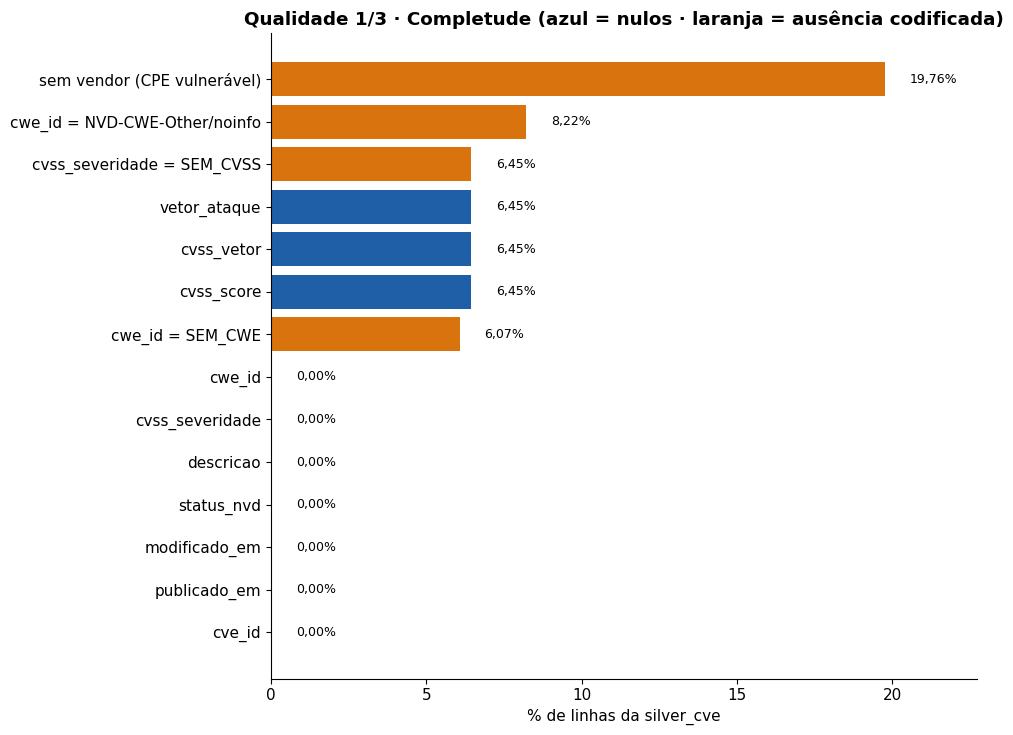

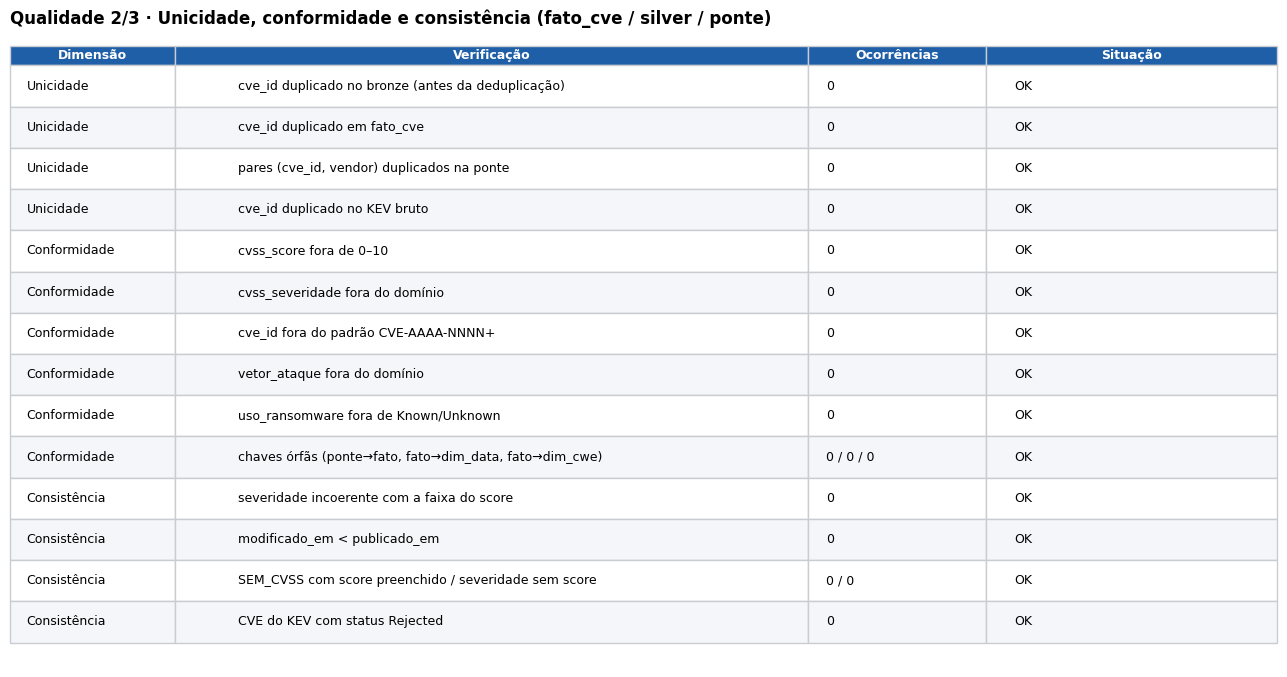

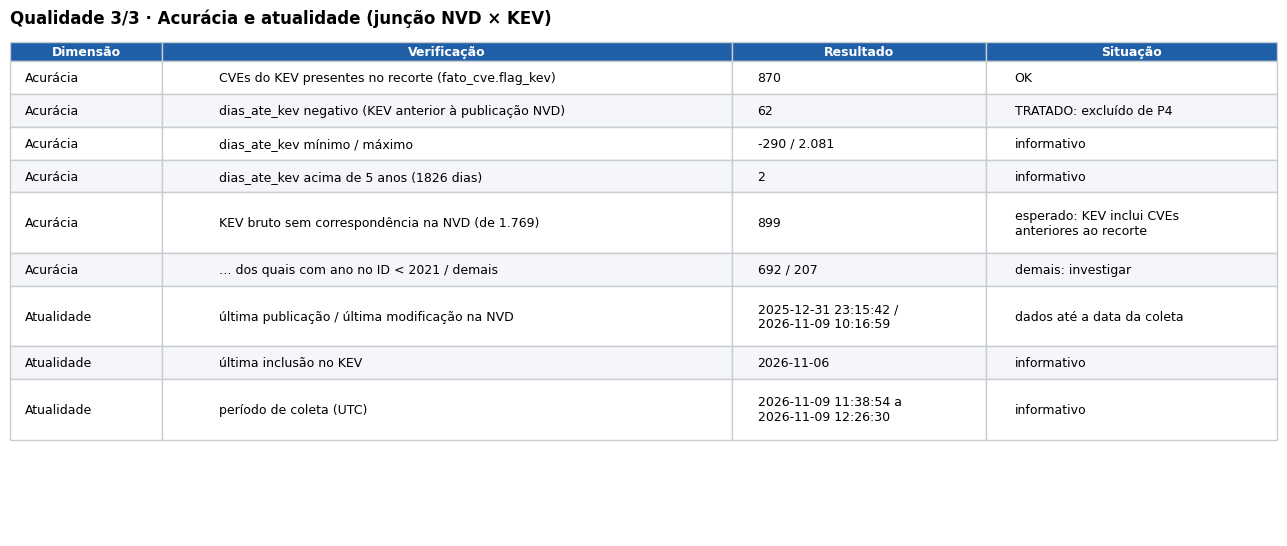

    Dimensão                                            Verificação Ocorrências Situação
   Unicidade     cve_id duplicado no bronze (antes da deduplicação)           0       OK
   Unicidade                           cve_id duplicado em fato_cve           0       OK
   Unicidade             pares (cve_id, vendor) duplicados na ponte           0       OK
   Unicidade                          cve_id duplicado no KEV bruto           0       OK
Conformidade                                cvss_score fora de 0–10           0       OK
Conformidade                        cvss_severidade fora do domínio           0       OK
Conformidade                   cve_id fora do padrão CVE-AAAA-NNNN+           0       OK
Conformidade                           vetor_ataque fora do domínio           0       OK
Conformidade                   uso_ransomware fora de Known/Unknown           0       OK
Conformidade chaves órfãs (ponte→fato, fato→dim_data, fato→dim_cwe)   0 / 0 / 0       OK
Consistência         

In [13]:
# ═══ CÉLULA 10 · Qualidade ═══
Q, DOM = {}, {}
sc = spark.table(f"{S}.silver_cve")
n_silver = sc.count()

# 1. Completude
nulos = sc.select([F.round(100 * F.avg(F.col(c).isNull().cast("int")), 2).alias(c) for c in sc.columns]).collect()[0].asDict()
r = sql("""SELECT SUM(CASE WHEN cvss_severidade = 'SEM_CVSS' THEN 1 ELSE 0 END) AS sem_cvss,
                  SUM(CASE WHEN cwe_id = 'SEM_CWE' THEN 1 ELSE 0 END) AS sem_cwe,
                  SUM(CASE WHEN cwe_id IN ('NVD-CWE-Other', 'NVD-CWE-noinfo') THEN 1 ELSE 0 END) AS cwe_generico,
                  COUNT(*) AS n FROM @S.silver_cve""").collect()[0]
sem_vendor = sql("SELECT COUNT(*) AS n FROM @S.silver_cve c LEFT ANTI JOIN @S.ponte_cve_vendor p ON c.cve_id = p.cve_id").collect()[0].n
comp = [(c, float(v), "nulo") for c, v in nulos.items()]
comp += [("cvss_severidade = SEM_CVSS", 100 * r.sem_cvss / n_silver, "ausência codificada"),
         ("cwe_id = SEM_CWE", 100 * r.sem_cwe / n_silver, "ausência codificada"),
         ("cwe_id = NVD-CWE-Other/noinfo", 100 * r.cwe_generico / n_silver, "CWE genérico"),
         ("sem vendor (CPE vulnerável)", 100 * sem_vendor / n_silver, "ausência na ponte")]
Q["comp"] = comp; Q["n_silver"] = n_silver
Q["sem_cvss_pct"] = 100 * r.sem_cvss / n_silver; Q["sem_vendor_pct"] = 100 * sem_vendor / n_silver
Q["cwe_ausente_pct"] = 100 * (r.sem_cwe + r.cwe_generico) / n_silver

ordem = sorted(comp, key=lambda x: x[1])
fig, ax = plt.subplots(figsize=(10, 0.42 * len(ordem) + 1.6))
cores = [AZUL if t == "nulo" else LARANJA for _, _, t in ordem]
ax.barh([o[0] for o in ordem], [o[1] for o in ordem], color=cores)
for i, o in enumerate(ordem):
    ax.text(o[1] + 0.8, i, pct(o[1], 2), va="center", fontsize=9)
ax.set_xlim(0, max(10, max(o[1] for o in ordem) * 1.15))
ax.set_xlabel("% de linhas da silver_cve"); ax.set_title("Qualidade 1/3 · Completude (azul = nulos · laranja = ausência codificada)")
fecha(f"{SAIDA}/qualidade_1_completude.png")

# 2. Unicidade
q_b = sql("SELECT COUNT(*) AS n, COUNT(DISTINCT upper(trim(id))) AS d FROM @S.bronze_nvd").collect()[0]
q_f = sql("SELECT COUNT(*) AS n, COUNT(DISTINCT cve_id) AS d FROM @S.fato_cve").collect()[0]
q_p = sql("SELECT COUNT(*) AS n, COUNT(DISTINCT cve_id, vendor) AS d FROM @S.ponte_cve_vendor").collect()[0]
q_k = sql("SELECT COUNT(*) AS n, COUNT(DISTINCT upper(trim(cveID))) AS d FROM @S.bronze_kev").collect()[0]
Q["dup_bronze"], Q["dup_fato"], Q["dup_ponte"], Q["dup_kev"] = q_b.n - q_b.d, q_f.n - q_f.d, q_p.n - q_p.d, q_k.n - q_k.d
Q["bronze_linhas"], Q["fato_linhas"] = q_b.n, q_f.n

# 3. Conformidade
c = sql(r"""SELECT SUM(CASE WHEN cvss_score < 0 OR cvss_score > 10 THEN 1 ELSE 0 END) AS score_fora,
       SUM(CASE WHEN cvss_severidade NOT IN ('LOW','MEDIUM','HIGH','CRITICAL','NONE','SEM_CVSS') THEN 1 ELSE 0 END) AS sev_invalida,
       SUM(CASE WHEN NOT cve_id RLIKE '^CVE-[0-9]{4}-[0-9]{4,}$' THEN 1 ELSE 0 END) AS id_fora,
       SUM(CASE WHEN vetor_ataque IS NOT NULL AND vetor_ataque NOT IN ('NETWORK','ADJACENT_NETWORK','LOCAL','PHYSICAL') THEN 1 ELSE 0 END) AS vetor_invalido,
       SUM(CASE WHEN uso_ransomware IS NOT NULL AND uso_ransomware NOT IN ('Known','Unknown') THEN 1 ELSE 0 END) AS ransom_invalido
       FROM @S.fato_cve""").collect()[0]
orf = sql("""SELECT (SELECT COUNT(*) FROM @S.ponte_cve_vendor p LEFT ANTI JOIN @S.fato_cve f ON p.cve_id = f.cve_id) AS ponte_orfa,
       (SELECT COUNT(*) FROM @S.fato_cve f LEFT ANTI JOIN @S.dim_data d ON f.sk_data_publicacao = d.sk_data) AS data_orfa,
       (SELECT COUNT(*) FROM @S.fato_cve f LEFT ANTI JOIN @S.dim_cwe d ON f.cwe_id = d.cwe_id) AS cwe_orfa""").collect()[0]
Q.update(score_fora=c.score_fora or 0, sev_invalida=c.sev_invalida or 0, id_fora=c.id_fora or 0, vetor_invalido=c.vetor_invalido or 0,
         ransom_invalido=c.ransom_invalido or 0, ponte_orfa=orf.ponte_orfa, data_orfa=orf.data_orfa, cwe_orfa=orf.cwe_orfa)

# 4. Consistência
con = sql("""SELECT
  (SELECT COUNT(*) FROM @S.fato_cve WHERE cvss_score IS NOT NULL AND NOT (
     (cvss_severidade = 'LOW' AND cvss_score BETWEEN 0.1 AND 3.9) OR (cvss_severidade = 'MEDIUM' AND cvss_score BETWEEN 4.0 AND 6.9) OR
     (cvss_severidade = 'HIGH' AND cvss_score BETWEEN 7.0 AND 8.9) OR (cvss_severidade = 'CRITICAL' AND cvss_score BETWEEN 9.0 AND 10.0) OR
     (cvss_severidade = 'NONE' AND cvss_score = 0))) AS sev_incoerente,
  (SELECT COUNT(*) FROM @S.silver_cve WHERE modificado_em < publicado_em) AS mod_antes_pub,
  (SELECT COUNT(*) FROM @S.fato_cve WHERE cvss_severidade = 'SEM_CVSS' AND cvss_score IS NOT NULL) AS semcvss_com_score,
  (SELECT COUNT(*) FROM @S.fato_cve WHERE cvss_severidade <> 'SEM_CVSS' AND cvss_score IS NULL) AS sev_sem_score,
  (SELECT COUNT(*) FROM @S.fato_cve WHERE flag_kev AND status_nvd = 'Rejected') AS kev_rejeitada""").collect()[0]
Q.update(sev_incoerente=con.sev_incoerente, mod_antes_pub=con.mod_antes_pub, semcvss_com_score=con.semcvss_com_score,
         sev_sem_score=con.sev_sem_score, kev_rejeitada=con.kev_rejeitada)

def _s(n, ok="OK", ruim="ATENÇÃO"):
    return ok if n == 0 else ruim
tab2 = pd.DataFrame([
    ("Unicidade", "cve_id duplicado no bronze (antes da deduplicação)", fmt(Q["dup_bronze"]), "TRATADO: dedup mantém maior lastModified" if Q["dup_bronze"] else "OK"),
    ("Unicidade", "cve_id duplicado em fato_cve", fmt(Q["dup_fato"]), _s(Q["dup_fato"])),
    ("Unicidade", "pares (cve_id, vendor) duplicados na ponte", fmt(Q["dup_ponte"]), _s(Q["dup_ponte"])),
    ("Unicidade", "cve_id duplicado no KEV bruto", fmt(Q["dup_kev"]), "TRATADO: mantém a 1ª inclusão" if Q["dup_kev"] else "OK"),
    ("Conformidade", "cvss_score fora de 0–10", fmt(Q["score_fora"]), _s(Q["score_fora"])),
    ("Conformidade", "cvss_severidade fora do domínio", fmt(Q["sev_invalida"]), _s(Q["sev_invalida"])),
    ("Conformidade", "cve_id fora do padrão CVE-AAAA-NNNN+", fmt(Q["id_fora"]), _s(Q["id_fora"])),
    ("Conformidade", "vetor_ataque fora do domínio", fmt(Q["vetor_invalido"]), _s(Q["vetor_invalido"])),
    ("Conformidade", "uso_ransomware fora de Known/Unknown", fmt(Q["ransom_invalido"]), _s(Q["ransom_invalido"])),
    ("Conformidade", "chaves órfãs (ponte→fato, fato→dim_data, fato→dim_cwe)", f"{fmt(Q['ponte_orfa'])} / {fmt(Q['data_orfa'])} / {fmt(Q['cwe_orfa'])}", _s(Q["ponte_orfa"] + Q["data_orfa"] + Q["cwe_orfa"])),
    ("Consistência", "severidade incoerente com a faixa do score", fmt(Q["sev_incoerente"]), _s(Q["sev_incoerente"])),
    ("Consistência", "modificado_em < publicado_em", fmt(Q["mod_antes_pub"]), _s(Q["mod_antes_pub"])),
    ("Consistência", "SEM_CVSS com score preenchido / severidade sem score", f"{fmt(Q['semcvss_com_score'])} / {fmt(Q['sev_sem_score'])}", _s(Q["semcvss_com_score"] + Q["sev_sem_score"])),
    ("Consistência", "CVE do KEV com status Rejected", fmt(Q["kev_rejeitada"]), _s(Q["kev_rejeitada"])),
], columns=["Dimensão", "Verificação", "Ocorrências", "Situação"])
tabela_png(tab2, "Qualidade 2/3 · Unicidade, conformidade e consistência (fato_cve / silver / ponte)",
           f"{SAIDA}/qualidade_2_unicidade_conformidade_consistencia.png", [0.13, 0.5, 0.14, 0.23], quebra=[16, 62, 18, 30])

# 5. Acurácia
a = sql("""SELECT COUNT(*) AS n_kev, SUM(CASE WHEN dias_ate_kev < 0 THEN 1 ELSE 0 END) AS neg,
       MIN(dias_ate_kev) AS mn, MAX(dias_ate_kev) AS mx,
       SUM(CASE WHEN dias_ate_kev > 1826 THEN 1 ELSE 0 END) AS acima_5a FROM @S.fato_cve WHERE flag_kev""").collect()[0]
sem = sql("""SELECT COUNT(*) AS n,
       SUM(CASE WHEN TRY_CAST(substr(k.cve_id, 5, 4) AS INT) < 2021 THEN 1 ELSE 0 END) AS id_anterior_2021
       FROM @S.silver_kev k LEFT ANTI JOIN @S.silver_cve c ON k.cve_id = c.cve_id""").collect()[0]
n_kev_total = sql("SELECT COUNT(*) AS n FROM @S.silver_kev").collect()[0].n
Q.update(kev_no_corte=a.n_kev, dias_neg=a.neg or 0, dias_min=a.mn, dias_max=a.mx, dias_acima_5a=a.acima_5a or 0,
         kev_total=n_kev_total, kev_sem_nvd=sem.n, kev_sem_nvd_id_antigo=sem.id_anterior_2021 or 0)
Q["kev_sem_nvd_outros"] = Q["kev_sem_nvd"] - Q["kev_sem_nvd_id_antigo"]

# 6. Atualidade
at = sql("SELECT MAX(publicado_em) AS pub, MAX(modificado_em) AS modi FROM @S.silver_cve").collect()[0]
kv = sql("SELECT MAX(kev_incluido_em) AS ult FROM @S.silver_kev").collect()[0]
Q.update(ult_pub=str(at.pub)[:19], ult_mod=str(at.modi)[:19], ult_kev=str(kv.ult))

tab3 = pd.DataFrame([
    ("Acurácia", "CVEs do KEV presentes no recorte (fato_cve.flag_kev)", fmt(Q["kev_no_corte"]), "OK"),
    ("Acurácia", "dias_ate_kev negativo (KEV anterior à publicação NVD)", fmt(Q["dias_neg"]), "TRATADO: excluído de P4" if Q["dias_neg"] else "OK"),
    ("Acurácia", "dias_ate_kev mínimo / máximo", f"{fmt(Q['dias_min'])} / {fmt(Q['dias_max'])}", "informativo"),
    ("Acurácia", "dias_ate_kev acima de 5 anos (1826 dias)", fmt(Q["dias_acima_5a"]), "informativo"),
    ("Acurácia", f"KEV bruto sem correspondência na NVD (de {fmt(Q['kev_total'])})", fmt(Q["kev_sem_nvd"]), "esperado: KEV inclui CVEs anteriores ao recorte"),
    ("Acurácia", "… dos quais com ano no ID < 2021 / demais", f"{fmt(Q['kev_sem_nvd_id_antigo'])} / {fmt(Q['kev_sem_nvd_outros'])}", "demais: investigar" if Q["kev_sem_nvd_outros"] else "OK"),
    ("Atualidade", "última publicação / última modificação na NVD", f"{Q['ult_pub']} / {Q['ult_mod']}", "dados até a data da coleta"),
    ("Atualidade", "última inclusão no KEV", Q["ult_kev"], "informativo"),
    ("Atualidade", "período de coleta (UTC)", f"{META['coleta_inicio_utc']} a {META['coleta_fim_utc']}", "informativo"),
], columns=["Dimensão", "Verificação", "Resultado", "Situação"])
tabela_png(tab3, "Qualidade 3/3 · Acurácia e atualidade (junção NVD × KEV)",
           f"{SAIDA}/qualidade_3_acuracia_atualidade.png", [0.12, 0.45, 0.2, 0.23], quebra=[14, 54, 26, 34])
print(tab2.to_string(index=False)); print(tab3.to_string(index=False))

# Domínios observados (alimentam o catálogo de dados)
d = sql("""SELECT MIN(cvss_score) AS smin, MAX(cvss_score) AS smax, MIN(sk_data_publicacao) AS dmin, MAX(sk_data_publicacao) AS dmax,
       MIN(kev_incluido_em) AS kmin, MAX(kev_incluido_em) AS kmax, MIN(modificado_em) AS mmin, MAX(modificado_em) AS mmax FROM @S.fato_cve""").collect()[0]
DOM.update(score=f"{d.smin} a {d.smax}", sk=f"{d.dmin} a {d.dmax}", kev=f"{d.kmin} a {d.kmax}", modif=f"{str(d.mmin)[:10]} a {str(d.mmax)[:10]}",
           dias=f"{Q['dias_min']} a {Q['dias_max']}")
for col in ("cvss_severidade", "vetor_ataque", "status_nvd", "uso_ransomware"):
    DOM[col] = ", ".join(str(x[0]) for x in sql(f"SELECT DISTINCT {col} FROM @S.fato_cve ORDER BY 1").collect())
DOM["cwe_tipos"] = ", ".join(str(x[0]) for x in sql("SELECT DISTINCT tipo FROM @S.dim_cwe ORDER BY 1").collect())
DOM["n_cwe"] = sql("SELECT COUNT(*) AS n FROM @S.dim_cwe").collect()[0].n
DOM["n_vendor"] = sql("SELECT COUNT(DISTINCT vendor) AS n FROM @S.ponte_cve_vendor").collect()[0].n

## Célula 11 · Análise P1–P5 (SQL sobre a gold) + gráficos PNG
Base de análise: `fato_cve` ⨝ `dim_data`, **excluindo status `Rejected`**. Divisões são feitas em pandas (o Spark está em modo ANSI).

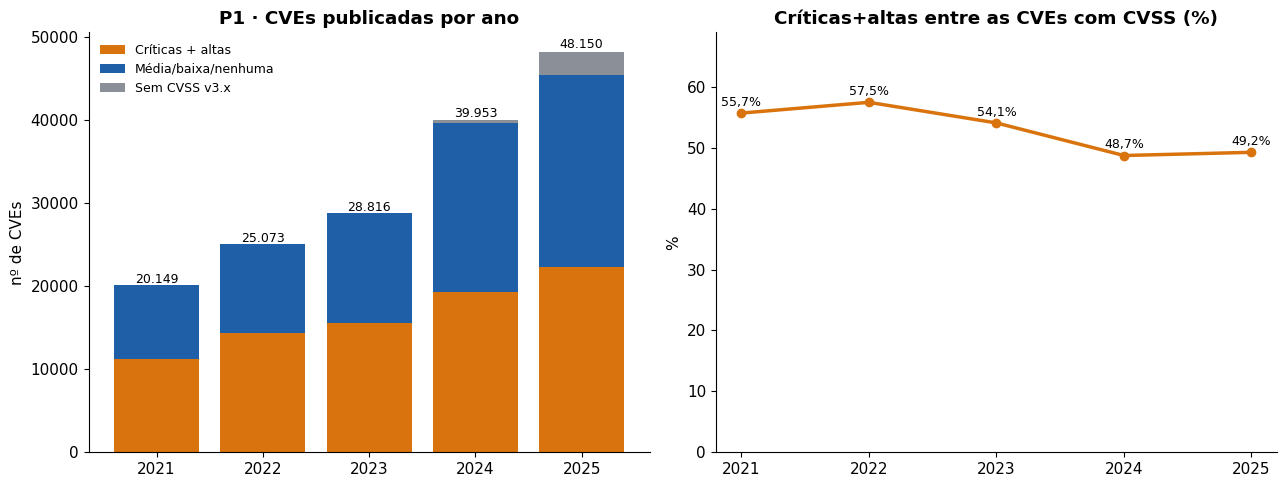

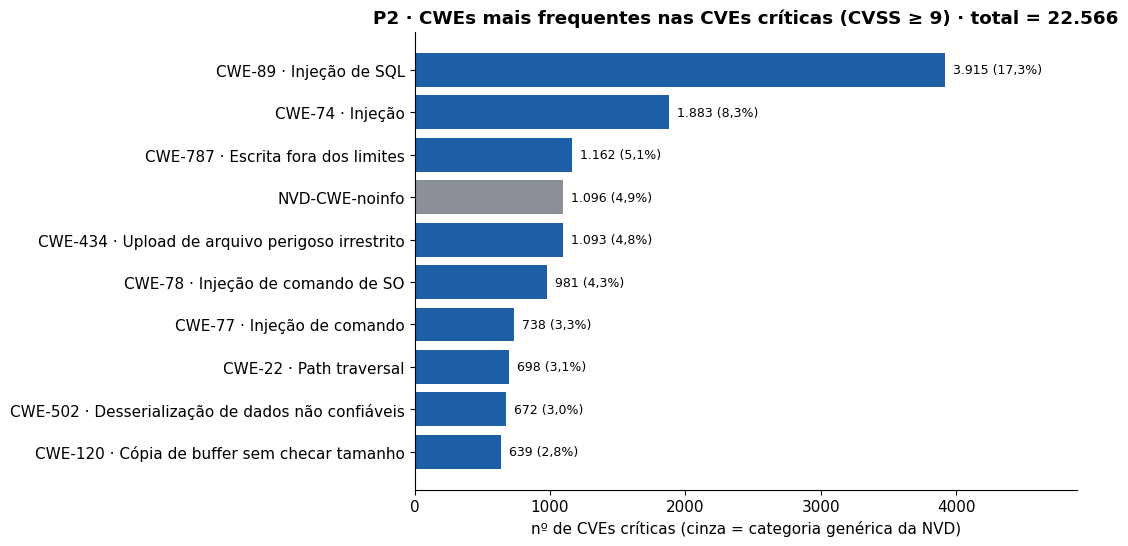

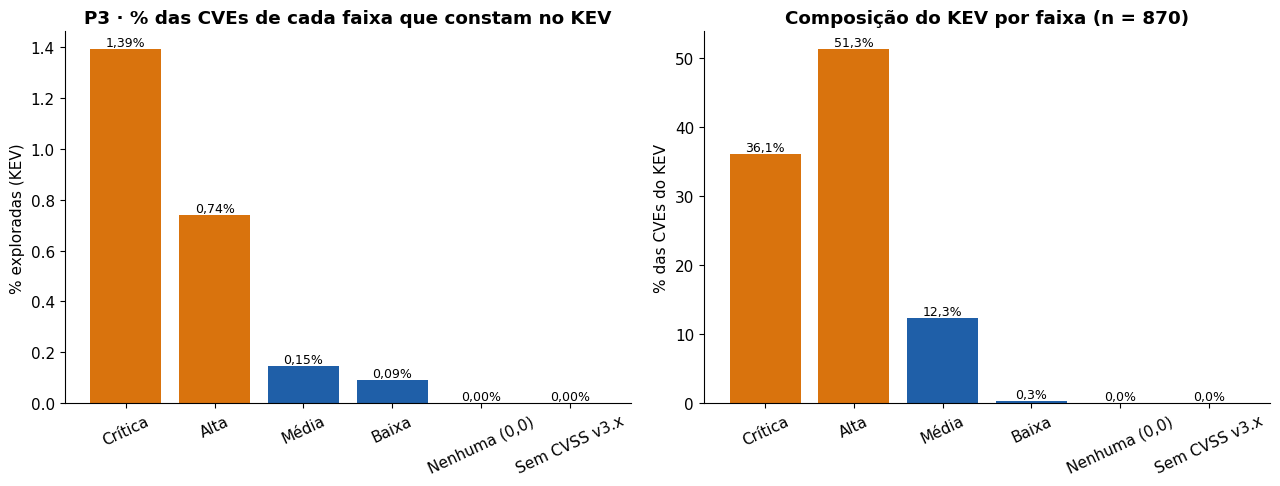

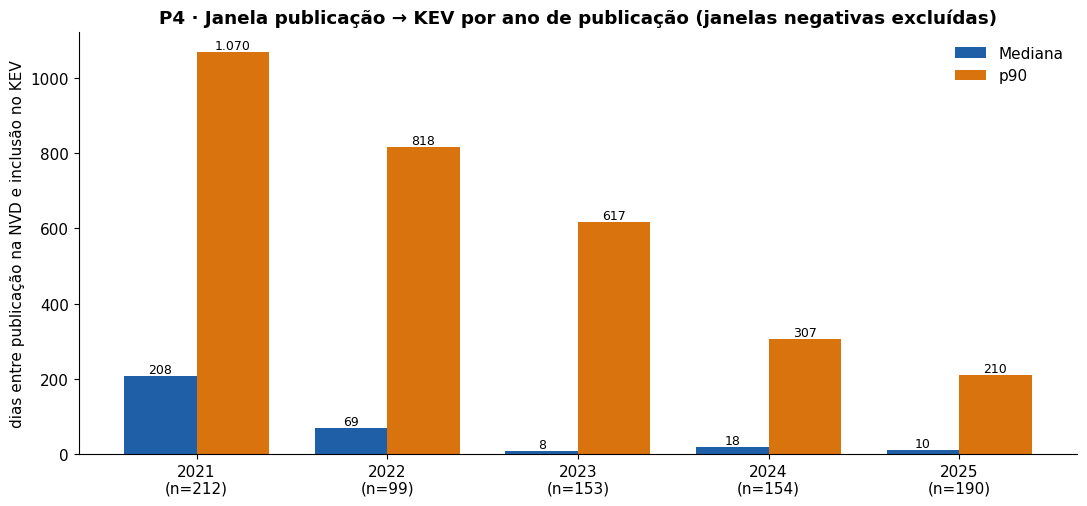

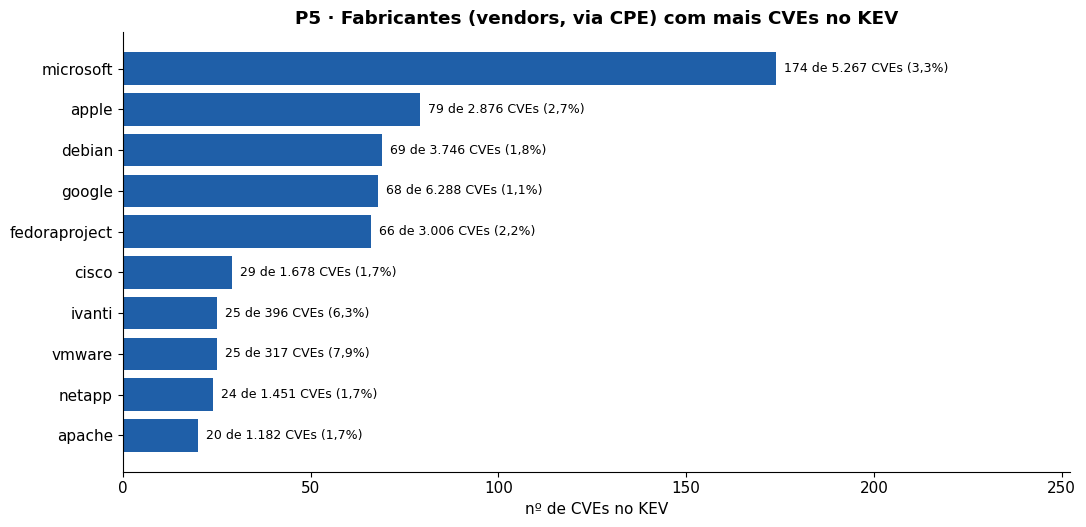


== P1 ==
    ano     cves  criticas_altas  criticas  sem_cvss  pontuadas     pct_ca   pct_sem
0  2021  20149.0         11220.0    2666.0       0.0    20149.0  55.685146  0.000000
1  2022  25073.0         14398.0    4247.0      12.0    25061.0  57.451818  0.047860
2  2023  28816.0         15580.0    4628.0       1.0    28815.0  54.069061  0.003470
3  2024  39953.0         19307.0    4938.0     324.0    39629.0  48.719372  0.810953
4  2025  48150.0         22349.0    6087.0    2765.0    45385.0  49.243142  5.742471

== P2 ==
            cwe_id                                     nome                    tipo  criticas        pct
0           CWE-89                           Injeção de SQL          CWE específico      3915  17.349109
1           CWE-74                                  Injeção          CWE específico      1883   8.344412
2          CWE-787                 Escrita fora dos limites          CWE específico      1162   5.149340
3   NVD-CWE-noinfo                                

In [14]:
# ═══ CÉLULA 11 · Análise ═══
sql("""SELECT f.*, d.ano FROM @S.fato_cve f JOIN @S.dim_data d ON f.sk_data_publicacao = d.sk_data
       WHERE coalesce(f.status_nvd, '') <> 'Rejected'""").createOrReplaceTempView("base")
spark.table("base").cache()
N_BASE = spark.table("base").count()
N_REJ = Q["fato_linhas"] - N_BASE
ORDEM_SEV = ["CRITICAL", "HIGH", "MEDIUM", "LOW", "NONE", "SEM_CVSS"]

# ---- P1 ----
p1 = to_pd(spark.sql("""SELECT ano, COUNT(*) AS cves,
    SUM(CASE WHEN cvss_severidade IN ('CRITICAL','HIGH') THEN 1 ELSE 0 END) AS criticas_altas,
    SUM(CASE WHEN cvss_severidade = 'CRITICAL' THEN 1 ELSE 0 END) AS criticas,
    SUM(CASE WHEN cvss_severidade = 'SEM_CVSS' THEN 1 ELSE 0 END) AS sem_cvss
    FROM base GROUP BY ano ORDER BY ano""")).astype(float)
p1["ano"] = p1["ano"].astype(int)
p1["pontuadas"] = p1.cves - p1.sem_cvss
p1["pct_ca"] = [100 * a / b if b > 0 else float("nan") for a, b in zip(p1.criticas_altas, p1.pontuadas)]
p1["pct_sem"] = 100 * p1.sem_cvss / p1.cves

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].bar(p1.ano, p1.criticas_altas, color=LARANJA, label="Críticas + altas")
ax[0].bar(p1.ano, p1.cves - p1.criticas_altas - p1.sem_cvss, bottom=p1.criticas_altas, color=AZUL, label="Média/baixa/nenhuma")
ax[0].bar(p1.ano, p1.sem_cvss, bottom=p1.cves - p1.sem_cvss, color=CINZA, label="Sem CVSS v3.x")
for x, v in zip(p1.ano, p1.cves):
    ax[0].text(x, v * 1.01, fmt(v), ha="center", fontsize=9)
ax[0].set_title("P1 · CVEs publicadas por ano"); ax[0].set_ylabel("nº de CVEs"); ax[0].legend(frameon=False, fontsize=9)
ax[1].plot(p1.ano, p1.pct_ca, marker="o", color=LARANJA, lw=2.5)
for x, v in zip(p1.ano, p1.pct_ca):
    ax[1].text(x, v + 1.2, pct(v), ha="center", fontsize=9)
ax[1].set_ylim(0, max(60, float(p1.pct_ca.max()) * 1.2)); ax[1].set_xticks(list(p1.ano))
ax[1].set_title("Críticas+altas entre as CVEs com CVSS (%)"); ax[1].set_ylabel("%")
fecha(f"{SAIDA}/p1.png")

# ---- P2 ----
p2 = to_pd(spark.sql("""SELECT f.cwe_id, c.nome, c.tipo, COUNT(*) AS criticas FROM base f JOIN mvp_cve.dim_cwe c ON f.cwe_id = c.cwe_id
    WHERE f.cvss_score >= 9 GROUP BY f.cwe_id, c.nome, c.tipo ORDER BY criticas DESC, f.cwe_id LIMIT 15"""))
p2["criticas"] = p2.criticas.astype(int)
N_CRIT = int(spark.sql("SELECT COUNT(*) AS n FROM base WHERE cvss_score >= 9").collect()[0].n)
p2["pct"] = 100 * p2.criticas / N_CRIT if N_CRIT else 0.0
p2_tipo = to_pd(spark.sql("""SELECT c.tipo, COUNT(*) AS n FROM base f JOIN mvp_cve.dim_cwe c ON f.cwe_id = c.cwe_id
    WHERE f.cvss_score >= 9 GROUP BY c.tipo""")).set_index("tipo").n.astype(int).to_dict()
top10 = p2.head(10).iloc[::-1]
rot = [r.cwe_id + (f" · {r.nome}" if isinstance(r.nome, str) else "") for r in top10.itertuples()]
fig, ax = plt.subplots(figsize=(11, 5.6))
ax.barh(rot, top10.criticas, color=[AZUL if t == "CWE específico" else CINZA for t in top10.tipo])
for i, (v, p) in enumerate(zip(top10.criticas, top10.pct)):
    ax.text(v, i, f"  {fmt(v)} ({pct(p)})", va="center", fontsize=9)
ax.set_xlim(0, float(top10.criticas.max()) * 1.25 if len(top10) else 1)
ax.set_title(f"P2 · CWEs mais frequentes nas CVEs críticas (CVSS ≥ 9) · total = {fmt(N_CRIT)}"); ax.set_xlabel("nº de CVEs críticas (cinza = categoria genérica da NVD)")
fecha(f"{SAIDA}/p2.png")

# ---- P3 ----
p3 = (to_pd(spark.sql("""SELECT cvss_severidade AS sev, COUNT(*) AS cves, SUM(CASE WHEN flag_kev THEN 1 ELSE 0 END) AS no_kev
      FROM base GROUP BY cvss_severidade""")).set_index("sev").astype(float).reindex(ORDEM_SEV).fillna(0))
p3["taxa"] = [100 * k / n if n > 0 else float("nan") for k, n in zip(p3.no_kev, p3.cves)]
KEV_TOT = float(p3.no_kev.sum()); CVE_TOT = float(p3.cves.sum())
p3["pct_kev"] = 100 * p3.no_kev / KEV_TOT if KEV_TOT else 0.0
BACKLOG = float(p3.loc[["CRITICAL", "HIGH"], "cves"].sum()); ACERTOS = float(p3.loc[["CRITICAL", "HIGH"], "no_kev"].sum())
PRECISAO = 100 * ACERTOS / BACKLOG if BACKLOG else float("nan")
COBERTURA = 100 * ACERTOS / KEV_TOT if KEV_TOT else float("nan")
TAXA_BASE = 100 * KEV_TOT / CVE_TOT if CVE_TOT else float("nan")
FORA = KEV_TOT - ACERTOS; FORA_SEM = float(p3.loc["SEM_CVSS", "no_kev"])
_t = [p3.loc[s_, "taxa"] for s_ in ["CRITICAL", "HIGH", "MEDIUM", "LOW"] if p3.loc[s_, "cves"] > 0]
MONOTONICA = all(x >= y for x, y in zip(_t, _t[1:]))
C1 = PRECISAO < LIM_PRECISAO; C2 = COBERTURA < LIM_COBERTURA
VEREDITO = "CONFIRMADA" if (C1 and C2) else ("PARCIALMENTE CONFIRMADA" if (C1 or C2) else "REFUTADA")

rot_sev = {"CRITICAL": "Crítica", "HIGH": "Alta", "MEDIUM": "Média", "LOW": "Baixa", "NONE": "Nenhuma (0,0)", "SEM_CVSS": "Sem CVSS v3.x"}
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
cs = [LARANJA, LARANJA, AZUL, AZUL, CINZA, CINZA]
ax[0].bar([rot_sev[i] for i in p3.index], p3.taxa.fillna(0), color=cs)
for i, v in enumerate(p3.taxa.fillna(0)):
    ax[0].text(i, v, pct(v, 2), ha="center", va="bottom", fontsize=9)
ax[0].set_title("P3 · % das CVEs de cada faixa que constam no KEV"); ax[0].set_ylabel("% exploradas (KEV)"); ax[0].tick_params(axis="x", rotation=25)
ax[1].bar([rot_sev[i] for i in p3.index], p3.pct_kev, color=cs)
for i, v in enumerate(p3.pct_kev):
    ax[1].text(i, v, pct(v), ha="center", va="bottom", fontsize=9)
ax[1].set_title(f"Composição do KEV por faixa (n = {fmt(KEV_TOT)})"); ax[1].set_ylabel("% das CVEs do KEV"); ax[1].tick_params(axis="x", rotation=25)
fecha(f"{SAIDA}/p3.png")

# ---- P4 ----
d4 = to_pd(spark.sql("SELECT ano, dias_ate_kev FROM base WHERE flag_kev"))
d4["dias_ate_kev"] = d4.dias_ate_kev.astype(float); d4["ano"] = d4.ano.astype(int)
neg4 = d4[d4.dias_ate_kev < 0]; ok4 = d4[d4.dias_ate_kev >= 0]
p4 = ok4.groupby("ano").dias_ate_kev.agg(n="count", mediana="median", p90=lambda x: x.quantile(0.9)).reset_index()
p4["pct30"] = [100 * (ok4[ok4.ano == a_].dias_ate_kev <= 30).mean() for a_ in p4.ano]
p4["neg"] = [int((neg4.ano == a_).sum()) for a_ in p4.ano]
P4_GLOBAL = dict(n=len(ok4), mediana=float(ok4.dias_ate_kev.median()) if len(ok4) else float("nan"),
                 p90=float(ok4.dias_ate_kev.quantile(0.9)) if len(ok4) else float("nan"),
                 pct30=100 * float((ok4.dias_ate_kev <= 30).mean()) if len(ok4) else float("nan"), neg=len(neg4))
fig, ax = plt.subplots(figsize=(11, 5.2))
xs = list(range(len(p4))); wd = 0.38
ax.bar([x - wd / 2 for x in xs], p4.mediana, wd, color=AZUL, label="Mediana")
ax.bar([x + wd / 2 for x in xs], p4.p90, wd, color=LARANJA, label="p90")
for x, m, p9, n_ in zip(xs, p4.mediana, p4.p90, p4.n):
    ax.text(x - wd / 2, m, fmt(m), ha="center", va="bottom", fontsize=9)
    ax.text(x + wd / 2, p9, fmt(p9), ha="center", va="bottom", fontsize=9)
ax.set_xticks(xs); ax.set_xticklabels([f"{a_}\n(n={int(n_)})" for a_, n_ in zip(p4.ano, p4.n)])
ax.set_ylabel("dias entre publicação na NVD e inclusão no KEV"); ax.legend(frameon=False)
ax.set_title("P4 · Janela publicação → KEV por ano de publicação (janelas negativas excluídas)")
fecha(f"{SAIDA}/p4.png")

# ---- P5 ----
p5 = to_pd(spark.sql("""SELECT p.vendor, COUNT(DISTINCT p.cve_id) AS cves_total,
    COUNT(DISTINCT CASE WHEN b.flag_kev THEN p.cve_id END) AS cves_kev
    FROM mvp_cve.ponte_cve_vendor p JOIN base b ON p.cve_id = b.cve_id
    GROUP BY p.vendor HAVING COUNT(DISTINCT CASE WHEN b.flag_kev THEN p.cve_id END) > 0
    ORDER BY cves_kev DESC, p.vendor LIMIT 15""")).astype({"cves_total": int, "cves_kev": int})
p5["pct_kev"] = 100 * p5.cves_kev / p5.cves_total
KEV_COM_VENDOR = int(spark.sql("SELECT COUNT(DISTINCT b.cve_id) AS n FROM base b JOIN mvp_cve.ponte_cve_vendor p ON b.cve_id = p.cve_id WHERE b.flag_kev").collect()[0].n)
p5_kev = to_pd(spark.sql("""SELECT k.vendor_kev AS vendor, COUNT(*) AS cves_kev FROM base b JOIN mvp_cve.silver_kev k ON b.cve_id = k.cve_id
    WHERE b.flag_kev GROUP BY k.vendor_kev ORDER BY cves_kev DESC, k.vendor_kev LIMIT 10""")).astype({"cves_kev": int})
t5 = p5.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 5.4))
ax.barh(t5.vendor, t5.cves_kev, color=AZUL)
for i, (v, tt, pp) in enumerate(zip(t5.cves_kev, t5.cves_total, t5.pct_kev)):
    ax.text(v, i, f"  {fmt(v)} de {fmt(tt)} CVEs ({pct(pp)})", va="center", fontsize=9)
ax.set_xlim(0, float(t5.cves_kev.max()) * 1.45 if len(t5) else 1)
ax.set_title("P5 · Fabricantes (vendors, via CPE) com mais CVEs no KEV"); ax.set_xlabel("nº de CVEs no KEV")
fecha(f"{SAIDA}/p5.png")

for nome_, df_ in (("P1", p1), ("P2", p2), ("P3", p3), ("P4", p4), ("P5", p5)):
    print(f"\n== {nome_} =="); print(df_.to_string())
print(f"\nPrecisão crít/alta = {PRECISAO:.2f}% | cobertura do KEV = {COBERTURA:.2f}% | veredito: {VEREDITO}")

## Célula 12 · `persistencia.png` (prova de gravação na nuvem)

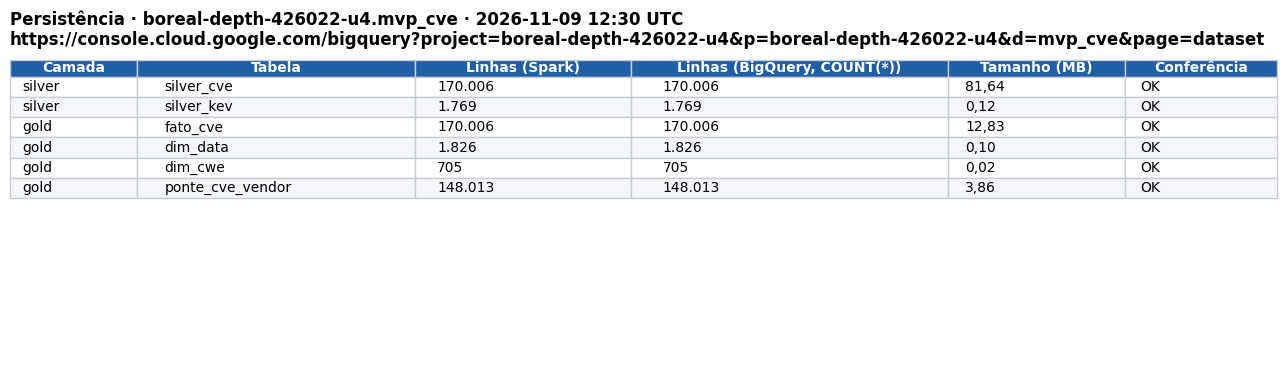

In [15]:
# ═══ CÉLULA 12 · Evidência de persistência ═══
agora = datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
tp = pd.DataFrame([(x["camada"], x["tabela"], fmt(x["linhas_spark"]), fmt(x["linhas_nuvem"]), fmt(x["mb"], 2),
                    "OK" if x["linhas_spark"] == x["linhas_nuvem"] else "DIVERGE") for x in PERSIST],
                  columns=["Camada", "Tabela", "Linhas (Spark)", "Linhas (BigQuery, COUNT(*))", "Tamanho (MB)", "Conferência"])
tabela_png(tp, f"Persistência · {BQ_LOCAL} · {agora}\n{BQ_URL}", f"{SAIDA}/persistencia.png",
           [0.1, 0.22, 0.17, 0.25, 0.14, 0.12], fonte=10, quebra=[12, 24, 16, 28, 14, 12])

## Célula 13 · Textos de discussão gerados por regras (todos os números vêm dos resultados acima)

In [16]:
# ═══ CÉLULA 13 · Discussões por regras ═══
def txt_p1():
    a, z = p1.iloc[0], p1.iloc[-1]
    var = (z.cves / a.cves - 1) * 100 if a.cves else float("nan")
    pico = p1.loc[p1.cves.idxmax()]
    media = 100 * p1.criticas_altas.sum() / p1.pontuadas.sum() if p1.pontuadas.sum() else float("nan")
    nivel = "parcela expressiva (40% ou mais)" if media >= 40 else ("parcela intermediária (entre 20% e 40%)" if media >= 20 else "parcela minoritária (menos de 20%)")
    t = (f"O volume anual de CVEs (excluídas as {fmt(N_REJ)} rejeitadas) foi de {fmt(a.cves)} em {int(a.ano)} e de {fmt(z.cves)} em {int(z.ano)}, "
         f"uma {'alta' if var >= 0 else 'queda'} de {pct(abs(var))}; o maior volume ocorreu em {int(pico.ano)} ({fmt(pico.cves)} CVEs). "
         f"Entre as CVEs que possuem CVSS v3.x, as críticas e altas representaram {pct(a.pct_ca)} em {int(a.ano)} e {pct(z.pct_ca)} em {int(z.ano)}, "
         f"com média de {pct(media)} no período — {nivel}. No total, a fila prioritária por CVSS (críticas + altas) soma {fmt(p1.criticas_altas.sum())} CVEs em {len(p1)} anos "
         f"(média de {fmt(p1.criticas_altas.mean())} por ano, ou cerca de {fmt(p1.criticas_altas.mean() / 365, 1)} por dia).")
    if z.pct_sem >= 20:
        t += (f" Atenção: {pct(z.pct_sem)} das CVEs de {int(z.ano)} não possuem CVSS v3.x na NVD (SEM_CVSS), de modo que a comparação do percentual de críticas/altas "
              f"nos anos mais recentes cobre apenas parte do universo.")
    return t

def txt_p2():
    esp = p2[p2.tipo == "CWE específico"].head(3)
    fr = "; ".join(f"{r.cwe_id}{' (' + r.nome + ')' if isinstance(r.nome, str) else ''} com {fmt(r.criticas)} CVEs ({pct(r.pct)})" for r in esp.itertuples())
    top5 = p2[p2.tipo == "CWE específico"].head(5)
    gen = p2_tipo.get("Categoria especial NVD", 0) + p2_tipo.get("Sem informação", 0)
    t = (f"Há {fmt(N_CRIT)} CVEs críticas (CVSS ≥ 9) no período. As três CWEs específicas mais frequentes entre elas são: {fr}. "
         f"As cinco principais CWEs específicas concentram {pct(top5.pct.sum())} das críticas. "
         f"Outras {fmt(gen)} CVEs críticas ({pct(100 * gen / N_CRIT if N_CRIT else float('nan'))}) estão classificadas em categorias genéricas da NVD "
         f"(NVD-CWE-Other/noinfo) ou sem CWE, o que limita a orientação de treinamento por tipo de falha.")
    return t

def txt_p3():
    L = lambda s_: p3.loc[s_]
    t = (f"Das {fmt(CVE_TOT)} CVEs do recorte, {fmt(KEV_TOT)} constam no KEV ({pct(TAXA_BASE, 2)}). A taxa de exploração por faixa foi: "
         f"crítica {pct(L('CRITICAL').taxa, 2)} ({fmt(L('CRITICAL').no_kev)} de {fmt(L('CRITICAL').cves)}), "
         f"alta {pct(L('HIGH').taxa, 2)} ({fmt(L('HIGH').no_kev)} de {fmt(L('HIGH').cves)}), "
         f"média {pct(L('MEDIUM').taxa, 2)} ({fmt(L('MEDIUM').no_kev)} de {fmt(L('MEDIUM').cves)}), "
         f"baixa {pct(L('LOW').taxa, 2)} ({fmt(L('LOW').no_kev)} de {fmt(L('LOW').cves)}) e "
         f"sem CVSS v3.x {pct(L('SEM_CVSS').taxa, 2)} ({fmt(L('SEM_CVSS').no_kev)} de {fmt(L('SEM_CVSS').cves)}). "
         f"A taxa {'decresce' if MONOTONICA else 'NÃO decresce monotonicamente'} da faixa crítica para a baixa. ")
    if L("MEDIUM").taxa and L("MEDIUM").taxa > 0:
        t += f"A taxa das críticas é {fmt(L('CRITICAL').taxa / L('MEDIUM').taxa, 1)} vez(es) a das médias. "
    t += (f"Priorizar críticas e altas implica corrigir {fmt(BACKLOG)} CVEs para alcançar {fmt(ACERTOS)} exploradas: precisão de {pct(PRECISAO, 2)} "
          f"(aproximadamente {fmt(100 / PRECISAO if PRECISAO else float('nan'), 0)} CVEs críticas/altas corrigidas para cada uma que consta no KEV; "
          f"{fmt(PRECISAO / TAXA_BASE if TAXA_BASE else float('nan'), 1)} vez(es) a taxa média do universo). "
          f"Quanto à cobertura, as faixas crítica e alta contêm {fmt(ACERTOS)} das {fmt(KEV_TOT)} CVEs do KEV ({pct(COBERTURA)}); "
          f"{fmt(FORA)} CVEs exploradas ({pct(100 - COBERTURA)}) ficam fora da fila crítica/alta, das quais {fmt(FORA_SEM)} não têm CVSS v3.x.")
    return t

def txt_p4():
    if not len(p4):
        return "Não há CVEs do KEV com janela não negativa no recorte; a pergunta não pôde ser respondida."
    G = P4_GLOBAL
    a, z = p4.iloc[0], p4.iloc[-1]
    t = (f"Considerando {fmt(G['n'])} CVEs do KEV com janela não negativa, a mediana entre a publicação na NVD e a inclusão no KEV foi de {fmt(G['mediana'])} dias "
         f"e o p90 de {fmt(G['p90'])} dias; {pct(G['pct30'])} entraram no KEV em até 30 dias. Por ano de publicação, a mediana foi de {fmt(a.mediana)} dias em {int(a.ano)} "
         f"e {fmt(z.mediana)} em {int(z.ano)}. Foram excluídas {fmt(G['neg'])} CVEs com janela negativa (incluídas no KEV antes de publicadas na NVD). ")
    if G["p90"] > 365:
        t += "A cauda é longa (p90 acima de um ano): parte relevante das CVEs só é reconhecida como explorada muito depois da publicação, de modo que um prazo (SLA) curto e único não captura esses casos e o monitoramento do KEV precisa ser contínuo. "
    else:
        t += "A maior parte das inclusões ocorre dentro de um ano da publicação, o que sustenta prazos (SLA) de correção relativamente curtos para CVEs do KEV. "
    t += (f"Cautela: há censura à direita — CVEs publicadas em anos mais recentes tiveram menos tempo de observação até a data da coleta ({META['coleta_fim_utc'][:10]}), "
          f"o que tende a reduzir mediana e p90 desses anos.")
    return t

def txt_p5():
    if not len(p5):
        return "Não foi possível mapear vendors para CVEs do KEV."
    cob = 100 * KEV_COM_VENDOR / KEV_TOT if KEV_TOT else float("nan")
    top = "; ".join(f"{r.vendor} ({fmt(r.cves_kev)})" for r in p5.head(5).itertuples())
    tk = "; ".join(f"{r.vendor} ({fmt(r.cves_kev)})" for r in p5_kev.head(5).itertuples())
    conc = 100 * p5.head(5).cves_kev.sum() / KEV_COM_VENDOR if KEV_COM_VENDOR else float("nan")
    t = (f"Pelo vendor extraído do CPE (apenas configurações marcadas como vulneráveis), os fabricantes com mais CVEs no KEV são: {top}. "
         f"Os cinco primeiros somam {fmt(p5.head(5).cves_kev.sum())} CVEs, ou {pct(conc)} das {fmt(KEV_COM_VENDOR)} CVEs do KEV que possuem vendor mapeado "
         f"(cobertura do mapeamento: {pct(cob)} das {fmt(KEV_TOT)} CVEs do KEV; uma CVE pode ter vários vendors, logo as contagens por vendor não são mutuamente exclusivas). "
         f"Verificação cruzada com o campo vendorProject do próprio KEV: {tk}.")
    return t

def txt_geral():
    t = (f"Critério declarado antes da execução: a hipótese é CONFIRMADA se (C1) a precisão das faixas crítica+alta for inferior a {fmt(LIM_PRECISAO, 0)}% "
         f"e (C2) a cobertura do KEV por essas faixas for inferior a {fmt(LIM_COBERTURA, 0)}%; PARCIALMENTE CONFIRMADA se apenas um dos dois critérios for atendido; REFUTADA se nenhum for. "
         f"Resultado: precisão = {pct(PRECISAO, 2)} (C1 {'atendido' if C1 else 'não atendido'}) e cobertura = {pct(COBERTURA)} (C2 {'atendido' if C2 else 'não atendido'}). "
         f"Veredito: hipótese {VEREDITO}. ")
    t += (f"A leitura literal da hipótese (a maioria das críticas/altas nunca é explorada) é {'satisfeita' if PRECISAO < 50 else 'não satisfeita'}, "
          f"pois {pct(100 - PRECISAO, 2)} das CVEs críticas/altas não constam no KEV. ")
    if VEREDITO == "CONFIRMADA":
        t += ("Implicação: usar apenas o CVSS como critério de priorização gera uma fila grande e de baixo rendimento e, ao mesmo tempo, deixa de fora uma parcela relevante das CVEs efetivamente exploradas. "
              "Uma política mais eficiente combina o CVSS com um sinal de exploração: tratar primeiro as CVEs presentes no KEV (e, em extensão futura, com alta probabilidade pelo EPSS) e usar o CVSS para ordenar o restante.")
    elif VEREDITO == "PARCIALMENTE CONFIRMADA":
        t += ("Implicação: o CVSS apresenta limitação em apenas uma das duas dimensões avaliadas "
              f"({'baixa precisão, isto é, fila grande' if C1 else 'cobertura incompleta do KEV'}); recomenda-se complementá-lo com o KEV, sem descartá-lo como filtro inicial.")
    else:
        t += "Implicação: nos dados analisados, o CVSS apresentou boa precisão e boa cobertura segundo os critérios adotados; a hipótese de ineficiência não se sustenta neste recorte."
    t += (" Ressalvas: o KEV registra apenas exploração conhecida e relevante para o governo dos EUA (subnotificação), "
          "e os critérios numéricos (10% e 90%) são uma escolha do autor, explicitada para que o resultado seja auditável; outros limiares podem alterar o veredito.")
    return t

def autoaval():
    obs = {}
    obs["P1"] = ("respondida" + (f"; ressalva: {pct(p1.iloc[-1].pct_sem)} das CVEs de {int(p1.iloc[-1].ano)} sem CVSS v3.x" if p1.iloc[-1].pct_sem >= 20 else ""))
    gen = p2_tipo.get("Categoria especial NVD", 0) + p2_tipo.get("Sem informação", 0)
    obs["P2"] = ("respondida" + (f"; ressalva: {pct(100 * gen / N_CRIT)} das críticas com CWE genérica/ausente" if N_CRIT and 100 * gen / N_CRIT >= 15 else ""))
    obs["P3"] = ("respondida" if KEV_TOT > 0 else "NÃO respondida: nenhuma CVE do recorte consta no KEV") + (f"; ressalva: {fmt(FORA_SEM)} CVEs do KEV sem CVSS v3.x" if FORA_SEM and KEV_TOT and FORA_SEM / KEV_TOT >= 0.10 else "")
    obs["P4"] = ("respondida" if len(p4) else "NÃO respondida: sem janelas válidas") + "; ressalva: censura à direita nos anos recentes"
    cob = 100 * KEV_COM_VENDOR / KEV_TOT if KEV_TOT else 0
    obs["P5"] = ("respondida" if cob >= 80 else f"respondida parcialmente (vendor mapeado para {pct(cob)} do KEV)")
    return obs

AV = autoaval()
print(txt_geral())

Critério declarado antes da execução: a hipótese é CONFIRMADA se (C1) a precisão das faixas crítica+alta for inferior a 10% e (C2) a cobertura do KEV por essas faixas for inferior a 90%; PARCIALMENTE CONFIRMADA se apenas um dos dois critérios for atendido; REFUTADA se nenhum for. Resultado: precisão = 0,92% (C1 atendido) e cobertura = 87,4% (C2 atendido). Veredito: hipótese CONFIRMADA. A leitura literal da hipótese (a maioria das críticas/altas nunca é explorada) é satisfeita, pois 99,08% das CVEs críticas/altas não constam no KEV. Implicação: usar apenas o CVSS como critério de priorização gera uma fila grande e de baixo rendimento e, ao mesmo tempo, deixa de fora uma parcela relevante das CVEs efetivamente exploradas. Uma política mais eficiente combina o CVSS com um sinal de exploração: tratar primeiro as CVEs presentes no KEV (e, em extensão futura, com alta probabilidade pelo EPSS) e usar o CVSS para ordenar o restante. Ressalvas: o KEV registra apenas exploração conhecida e relev

## Célula 14 · Geração de `README.md`, `catalogo_dados.md`, `short_paper.tex`, `LICENSE`

In [17]:
# ═══ CÉLULA 14 · Documentos ═══
BANNER = "" if not MODO_TESTE else "> ⚠️ **DADOS SINTÉTICOS — execução de teste do pipeline. Não usar como resultado.**\n\n"
FIM_TXT = f"{FIM:%d/%m/%Y}"; INI_TXT = f"{INICIO:%d/%m/%Y}"
ANOS = f"{INICIO.year}–{FIM.year}"

def tab_p1():
    d = pd.DataFrame({"Ano": p1.ano, "CVEs": [fmt(v) for v in p1.cves], "Críticas+altas": [fmt(v) for v in p1.criticas_altas],
                      "% crít./altas (c/ CVSS)": [pct(v) for v in p1.pct_ca], "Sem CVSS v3.x": [fmt(v) for v in p1.sem_cvss], "% sem CVSS": [pct(v) for v in p1.pct_sem]})
    return md_tabela(d)
def tab_p2():
    d = pd.DataFrame({"CWE": p2.cwe_id, "Nome": [n if isinstance(n, str) else "—" for n in p2.nome], "Críticas": [fmt(v) for v in p2.criticas], "% das críticas": [pct(v) for v in p2.pct]})
    return md_tabela(d)
def tab_p3():
    d = pd.DataFrame({"Faixa": [rot_sev[i] for i in p3.index], "CVEs": [fmt(v) for v in p3.cves], "No KEV": [fmt(v) for v in p3.no_kev],
                      "% exploradas": [pct(v, 2) for v in p3.taxa], "% do KEV": [pct(v) for v in p3.pct_kev]})
    return md_tabela(d)
def tab_p4():
    d = pd.DataFrame({"Ano": p4.ano, "CVEs no KEV (n)": [fmt(v) for v in p4.n], "Mediana (dias)": [fmt(v) for v in p4.mediana], "p90 (dias)": [fmt(v) for v in p4.p90],
                      "% em até 30 dias": [pct(v) for v in p4.pct30], "Excluídas (<0)": [fmt(v) for v in p4.neg]})
    return md_tabela(d)
def tab_p5():
    d = pd.DataFrame({"Vendor (CPE)": p5.vendor, "CVEs": [fmt(v) for v in p5.cves_total], "No KEV": [fmt(v) for v in p5.cves_kev], "% no KEV": [pct(v, 2) for v in p5.pct_kev]})
    return md_tabela(d)

QUAL = pd.DataFrame([
    ("Completude", "% de nulos por atributo (silver_cve) e ausências codificadas",
     f"Nulos relevantes: cvss_score/vetor {pct(dict((x[0], x[1]) for x in Q['comp'])['cvss_score'], 1)}; SEM_CVSS {pct(Q['sem_cvss_pct'], 1)}; CWE genérico/ausente {pct(Q['cwe_ausente_pct'], 1)}; sem vendor {pct(Q['sem_vendor_pct'], 1)}",
     "CVSS ausente → SEM_CVSS (mantida, fora de P2); CWE ausente → SEM_CWE; vendor ausente fica fora de P5 (cobertura medida)"),
    ("Unicidade", "`cve_id` duplicado (bronze, fato, ponte, KEV)",
     f"bronze: {fmt(Q['dup_bronze'])}; fato: {fmt(Q['dup_fato'])}; ponte: {fmt(Q['dup_ponte'])}; KEV: {fmt(Q['dup_kev'])}", "Deduplicação na silver (maior `lastModified`; KEV: 1ª inclusão)"),
    ("Conformidade", "score 0–10, severidade, padrão do ID, vetor, ransomware, chaves órfãs",
     f"fora do domínio: score {fmt(Q['score_fora'])}, severidade {fmt(Q['sev_invalida'])}, ID {fmt(Q['id_fora'])}, vetor {fmt(Q['vetor_invalido'])}, ransomware {fmt(Q['ransom_invalido'])}; órfãs {fmt(Q['ponte_orfa'] + Q['data_orfa'] + Q['cwe_orfa'])}",
     "Nenhum tratamento necessário" if (Q['score_fora'] + Q['sev_invalida'] + Q['id_fora'] + Q['vetor_invalido'] + Q['ransom_invalido'] + Q['ponte_orfa'] + Q['data_orfa'] + Q['cwe_orfa']) == 0 else "Registros listados em `qualidade_2_*.png`; avaliar caso a caso"),
    ("Consistência", "severidade × faixa do score; modificação ≥ publicação",
     f"severidade incoerente: {fmt(Q['sev_incoerente'])}; modificado antes de publicado: {fmt(Q['mod_antes_pub'])}; KEV com status Rejected: {fmt(Q['kev_rejeitada'])}",
     "CVEs `Rejected` excluídas de todas as análises"),
    ("Acurácia", "`dias_ate_kev` negativo; KEV sem correspondência na NVD",
     f"negativos: {fmt(Q['dias_neg'])} de {fmt(Q['kev_no_corte'])} (mín. {fmt(Q['dias_min'])}, máx. {fmt(Q['dias_max'])}); KEV sem NVD no recorte: {fmt(Q['kev_sem_nvd'])} ({fmt(Q['kev_sem_nvd_id_antigo'])} com ano no ID < {INICIO.year})",
     "Janelas negativas excluídas de P4 (reportadas); KEV anterior ao recorte é esperado e não entra na análise"),
    ("Atualidade", "última publicação/modificação/inclusão no KEV",
     f"publicação {Q['ult_pub']}; modificação {Q['ult_mod']}; KEV {Q['ult_kev']}", "—"),
], columns=["Dimensão", "Verificação", "Resultado", "Tratamento"])

README = f"""# MVP — O CVSS é um bom critério para priorizar a correção de vulnerabilidades?

**Pipeline de dados em nuvem (Google Colab + PySpark + BigQuery Sandbox) com NVD + CISA KEV**
Universidade de Brasília · Departamento de Engenharia de Produção · Prof. André Luiz Marques Serrano
Aluno: Daniel de Carvalho Vianna (matrícula 231013322) · Trabalho individual

{BANNER}---

## 1. Objetivo

### 1.1 Problema
Equipes de TI recebem milhares de novas vulnerabilidades (CVEs) por ano e têm capacidade de correção limitada: é um problema clássico de **alocação de recursos escassos sob risco**, central na Engenharia de Produção. A prática mais comum é priorizar pela severidade CVSS (críticas e altas primeiro). Este MVP testa se essa regra é eficiente, comparando a severidade publicada na NVD com a **exploração real** das vulnerabilidades, medida pelo catálogo KEV (Known Exploited Vulnerabilities) da CISA.

**Recorte:** CVEs publicadas de {INI_TXT} a {FIM_TXT}. O KEV só existe desde novembro de 2021; por isso o período de análise de P1 e P4 foi fixado em {ANOS}.

### 1.2 Hipótese
> Priorizar apenas por CVSS gera um backlog grande e pouco eficiente: a maioria das CVEs críticas/altas nunca é explorada e uma parcela relevante das exploradas fica fora da faixa crítica/alta.

A hipótese é refutável: se a taxa de exploração crescer fortemente com a severidade e as faixas crítica/alta cobrirem quase todo o KEV, o CVSS é um bom priorizador.

**Critério de veredito (definido antes da execução):** C1 = precisão das faixas crítica+alta (% dessas CVEs que constam no KEV) < {fmt(LIM_PRECISAO, 0)}%; C2 = cobertura (% do KEV contido nas faixas crítica+alta) < {fmt(LIM_COBERTURA, 0)}%. Confirmada se C1 e C2; parcialmente confirmada se só um; refutada se nenhum. Os limiares são escolha do autor.

### 1.3 Perguntas de negócio
| # | Pergunta | Decisão que apoia |
|---|---|---|
| P1 | Como evoluiu, de {INICIO.year} a {FIM.year}, o volume anual de CVEs e a participação de críticas/altas? | Dimensionar a carga de trabalho de correção |
| P2 | Quais CWEs (tipos de falha) concentram as CVEs críticas (CVSS ≥ 9)? | Direcionar treinamento e revisão de código |
| P3 | Que fração das CVEs de cada faixa de severidade consta no KEV, e que parcela do KEV é coberta por críticas/altas? | Avaliar a eficiência de priorizar só por CVSS |
| P4 | Qual a janela (mediana, p90) entre a publicação da CVE e sua inclusão no KEV, por ano? | Definir prazos (SLA) de correção |
| P5 | Quais fabricantes (vendors) concentram CVEs exploradas? | Priorizar inventário e monitoramento de ativos |

> Se alguma pergunta não for plenamente respondida, ela permanece nesta lista e é discutida na autoavaliação (seção 8). O período de P1 (originalmente 2016 até o último ano completo) foi ajustado para {ANOS} pelo motivo do recorte acima.

## 2. Plataforma e arquitetura

- **Plataforma:** Google Colab (execução) + **BigQuery Sandbox** (persistência na nuvem; gratuito, sem cartão). Custo de operação: zero (Colab gratuito, API pública da NVD sem chave, BigQuery Sandbox). No Sandbox as tabelas expiram por padrão em 60 dias; as evidências em PNG deste repositório registram o estado da carga.
- **Arquitetura medalhão:** raw (arquivos JSON/CSV no disco do Colab) → bronze (tabelas Spark, dado como veio) → silver (limpo/tipado, regras de negócio) → gold (modelo estrela). **Silver e gold são gravadas no BigQuery**.
- **Linguagens:** Python (coleta e ETL com PySpark local, versão 3.5.3, modo ANSI ligado) e SQL (qualidade e análise).
- **Execução:** um único notebook, [`{NOTEBOOK}`]({NOTEBOOK}), executável com "Executar tudo".

## 3. Dados

| Fonte | Conteúdo | Licença / termos | Formato original |
|---|---|---|---|
| [NVD API 2.0](https://nvd.nist.gov/developers/vulnerabilities) (NIST) | CVEs: datas, CVSS, CWE, configurações afetadas (CPE) | Dados do governo dos EUA, de uso público; [termos de uso da API](https://nvd.nist.gov/developers/terms-of-use) | JSON paginado ({META['resultados_por_pagina']} CVEs/página, janelas de {META['janela_dias']} dias) |
| [CISA KEV](https://www.cisa.gov/known-exploited-vulnerabilities-catalog) | CVEs com exploração confirmada, data de inclusão, uso em ransomware | Dados públicos do governo dos EUA | CSV |

- **Data da coleta:** {META['coleta_inicio_utc']} a {META['coleta_fim_utc']} (UTC); registro completo em `coleta_meta.json`.
- **Volume obtido:** NVD: {fmt(META['nvd_cves_baixadas'])} CVEs em {fmt(META['n_arquivos_nvd'])} arquivos JSON ({fmt(META['mb_nvd'], 1)} MB), em {META['n_janelas']} janelas de até {META['janela_dias']} dias, sem chave de API (pausa de {PAUSA_S} s entre requisições). O total anunciado pela API ({fmt(META['nvd_total_anunciado_api'])}) foi conferido, janela a janela, com o total gravado: {"coincidem em todas as janelas" if not META['janelas_incompletas'] else "DIVERGÊNCIAS: " + str(META['janelas_incompletas'])}. KEV: {fmt(META['kev_linhas'])} linhas ({fmt(META['kev_bytes'] / 1e3, 1)} KB).
- **Dados pessoais (LGPD):** a base não contém dados pessoais (apenas identificadores de vulnerabilidades e metadados técnicos). **Dados corporativos:** nenhum.
- Os dados brutos **não** são versionados no GitHub (volume); o notebook reproduz a obtenção.

## 4. Modelagem

Modelo **estrela** na camada gold (grão da fato: uma CVE):
`fato_cve` · `dim_data` · `dim_cwe` · `ponte_cve_vendor` (N:N). Diagrama, **Catálogo de Dados completo (domínios, obrigatoriedade e linhagem)** em [`catalogo_dados.md`](catalogo_dados.md).

## 5. Carga (ETL)

O notebook [`{NOTEBOOK}`]({NOTEBOOK}) executa, em ordem:

| Células | Função |
|---|---|
| 1–3 | Configuração, autenticação Google (única ação humana), projeto/dataset no BigQuery, dependências |
| 4 | Coleta: NVD em janelas de {META['janela_dias']} dias (retry com backoff, retomada, auditoria) e KEV |
| 5 | Spark local e camada **bronze** |
| 6 | Camada **silver** (limpeza, tipagem, regras de negócio) |
| 7 | Camada **gold** (modelo estrela) |
| 8 | Carga **silver + gold no BigQuery** e conferência de contagens |
| 10 | Qualidade (6 dimensões) |
| 11–12 | Análise P1–P5, gráficos e evidência de persistência |
| 13–15 | Geração automática de README, catálogo, paper (.tex) e .zip |

**Regras de negócio aplicadas na transformação**
1. CVSS: métrica v3.1; se ausente, v3.0; se ausente, `SEM_CVSS`. Dentro de cada versão, usa-se a entrada `Primary` (NVD) quando existe; senão, a primeira listada (pode ser de uma CNA). CVSS v4.0 não é utilizado.
2. Descrição: apenas em inglês.
3. CWE: primeiro CWE listado; ausência vira `SEM_CWE`.
4. Vendors: extraídos do CPE 2.3 (4º segmento, minúsculo) **apenas das correspondências marcadas como vulneráveis** (`vulnerable = true`), para não contar plataformas onde o produto apenas executa; uma CVE pode ter vários vendors (tabela ponte).
5. Junção NVD ↔ KEV pela chave `cve_id` (maiúsculas, sem espaços), com *left join* a partir da NVD.
6. Deduplicação: uma linha por `cve_id`, mantendo a de maior `lastModified` (KEV: mantém a primeira inclusão).
7. `dias_ate_kev` = data de inclusão no KEV − data de publicação na NVD; valores negativos são mantidos na gold e excluídos de P4.
8. CVEs com status `Rejected` são excluídas das análises.
9. Recorte: CVEs com data de publicação de {INI_TXT} a {FIM_TXT}.

**Persistência na nuvem:** projeto/dataset `{BQ_LOCAL}`; console: {BQ_URL}. Evidência: ![Persistência](persistencia.png)

## 6. Qualidade dos dados

Executada na célula 10 do notebook (completude, unicidade, conformidade, consistência, acurácia, atualidade).

{md_tabela(QUAL)}

Evidências: ![Qualidade 1](qualidade_1_completude.png) ![Qualidade 2](qualidade_2_unicidade_conformidade_consistencia.png) ![Qualidade 3](qualidade_3_acuracia_atualidade.png)

## 7. Resultados e discussão

Base de análise: {fmt(N_BASE)} CVEs publicadas de {INI_TXT} a {FIM_TXT} (excluídas {fmt(N_REJ)} com status `Rejected`).

### P1 — Evolução anual
![P1](p1.png)

{tab_p1()}

**Resultado e discussão:** {txt_p1()}

### P2 — CWEs das CVEs críticas
![P2](p2.png)

{tab_p2()}

**Resultado e discussão:** {txt_p2()}

### P3 — Exploração por faixa de severidade
![P3](p3.png)

{tab_p3()}

**Resultado e discussão:** {txt_p3()}

### P4 — Janela publicação → KEV
![P4](p4.png)

{tab_p4()}

**Resultado e discussão:** {txt_p4()}

### P5 — Vendors com mais CVEs exploradas
![P5](p5.png)

{tab_p5()}

**Resultado e discussão:** {txt_p5()}

### Discussão geral
{txt_geral()}

## 8. Autoavaliação

1. **Perguntas respondidas / não respondidas e por quê:** P1 — {AV['P1']}. P2 — {AV['P2']}. P3 — {AV['P3']}. P4 — {AV['P4']}. P5 — {AV['P5']}.
2. **Limitações dos dados:**
   - O KEV só existe desde 2021 e cobre exploração *conhecida*; CVEs fora do KEV podem ter sido exploradas sem registro (subnotificação). Por isso o recorte começa em {INICIO.year}.
   - {pct(Q['sem_cvss_pct'], 1)} das CVEs do recorte não têm CVSS v3.x (`SEM_CVSS`), principalmente as mais recentes e as aguardando análise na NVD; CVSS v4.0 não foi considerado.
   - Vendor extraído do CPE: {pct(Q['sem_vendor_pct'], 1)} das CVEs não têm vendor mapeado (configuração não preenchida).
   - O KEV tem viés de relevância para o governo dos EUA e para produtos amplamente usados.
   - Censura à direita: CVEs publicadas em {FIM.year} tiveram pouco tempo para entrar no KEV até a coleta ({META['coleta_fim_utc'][:10]}), o que afeta P3 e P4.
   - Os limiares do veredito (C1 e C2) são arbitrários, ainda que declarados.
3. **Decisões técnicas que mudaria:** usar BigQuery SQL (ou pandas) diretamente em vez de Spark local, que é desnecessário para este volume; coletar com chave de API da NVD para acelerar a coleta; persistir os dados brutos na nuvem (por exemplo, no Cloud Storage), não apenas as tabelas silver/gold; incluir CVSS v4.0 e a data de publicação da CNA.
4. **Extensões para uso contínuo:** coleta incremental (parâmetro `lastModStartDate` da API), orquestração agendada, inclusão do EPSS (probabilidade de exploração), comparação CVSS × KEV × EPSS, alertas por vendor presente no inventário da organização.

## 9. Como reproduzir
1. Abra https://console.cloud.google.com/bigquery com a conta Google que será usada e aceite o modo Sandbox (cria o projeto gratuito).
2. Abra o notebook [`{NOTEBOOK}`]({NOTEBOOK}) no [Google Colab](https://colab.research.google.com) (Arquivo → Fazer upload de notebook).
3. Execute **Ambiente de execução → Executar tudo** e autorize o acesso à conta Google quando solicitado (única interação).
4. Aguarde (cerca de 1 hora, limitada pelo limite de requisições da NVD sem chave). Se o Colab desconectar, execute tudo de novo: a coleta é retomável enquanto o ambiente não for reiniciado.
5. Os arquivos gerados ficam em `saida/` e são baixados ao final (arquivos soltos e `saida.zip`).

## 10. Estrutura do repositório
Repositório com estrutura plana (todos os arquivos na raiz):
```
README.md · LICENSE
{NOTEBOOK}           (pipeline completo: coleta, ETL, BigQuery, qualidade, análise, geração de documentos)
catalogo_dados.md    (catálogo de dados + diagrama + linhagem)
coleta_meta.json     (data, volume e formato da coleta)
short_paper.tex      (artigo curto para o Overleaf; usa p1.png … p5.png)
persistencia.png · qualidade_1_*.png · qualidade_2_*.png · qualidade_3_*.png · p1.png … p5.png   (evidências)
```
"""
with open(f"{SAIDA}/README.md", "w", encoding="utf-8") as f:
    f.write(README)
print("README.md:", len(README), "caracteres")

README.md: 18790 caracteres


In [18]:
# ═══ CÉLULA 14b · catalogo_dados.md ═══
def _n(col):  # % de nulos observado na silver
    return pct(dict((x[0], x[1]) for x in Q["comp"]).get(col, 0.0), 2)

CAT = f"""# Catálogo de Dados

{BANNER}Plataforma: Google Colab (PySpark) → **BigQuery Sandbox** (`{BQ_LOCAL}`). Modelo: **estrela** na camada gold. Recorte: CVEs publicadas de {INI_TXT} a {FIM_TXT}.
Colunas "observado" foram calculadas pelo notebook sobre os dados reais carregados.

## Diagrama do modelo

```mermaid
erDiagram
    dim_data ||--o{{ fato_cve : "sk_data = sk_data_publicacao"
    dim_cwe ||--o{{ fato_cve : "cwe_id"
    fato_cve ||--o{{ ponte_cve_vendor : "cve_id"
```

```
dim_data (sk_data PK) ──┐
                        ├── fato_cve (cve_id PK) ──── dim_cwe (cwe_id PK)
                        │         │
                        │         └── ponte_cve_vendor (cve_id, vendor)  [N:N]
```

## Linhagem geral

| Origem | Como foi obtida | Raw | Bronze | Silver | Gold |
|---|---|---|---|---|---|
| NVD (NIST) API 2.0 | Notebook `{NOTEBOOK}`, célula 4: JSON em janelas de {META['janela_dias']} dias por data de publicação, {META['resultados_por_pagina']} CVEs/página, sem chave | `raw/nvd/*.json` | `bronze_nvd` | `silver_cve`, `silver_cve_vendor` | `fato_cve`, `dim_cwe`, `ponte_cve_vendor` |
| CISA KEV | Mesmo notebook (CSV) | `raw/kev/kev.csv` | `bronze_kev` | `silver_kev` | colunas `flag_kev`, `kev_incluido_em`, `dias_ate_kev`, `uso_ransomware` em `fato_cve` |
| Calendário | Gerado por SQL (`sequence`) entre {INICIO} e {FIM} | — | — | — | `dim_data` |

Data da coleta: **{META['coleta_inicio_utc']} a {META['coleta_fim_utc']} UTC** · NVD: {fmt(META['nvd_cves_baixadas'])} CVEs, {fmt(META['mb_nvd'], 1)} MB · KEV: {fmt(META['kev_linhas'])} linhas.
Tabelas no BigQuery: {", ".join("`" + t + "`" for t in TABELAS_BQ)}.

## fato_cve (grão: uma CVE) — {fmt(Q['fato_linhas'])} linhas

| Atributo | Tipo | Descrição | Domínio esperado | Domínio observado | Nulos? | Linhagem |
|---|---|---|---|---|---|---|
| cve_id | texto | Identificador da CVE | padrão `CVE-AAAA-NNNN+` | {fmt(Q['fato_linhas'])} distintos | Não | NVD `cve.id`, maiúsculas/trim |
| sk_data_publicacao | inteiro | Chave para `dim_data` (yyyyMMdd) | {INICIO:%Y%m%d} a {FIM:%Y%m%d} | {DOM['sk']} | Não | NVD `published` → data |
| cvss_score | numérico | Nota base CVSS | 0,0 a 10,0 | {DOM['score']} | Sim: sem CVSS v3.x ({_n('cvss_score')} na silver) | NVD métrica v3.1; senão v3.0 |
| cvss_severidade | categórico | Faixa de severidade | LOW, MEDIUM, HIGH, CRITICAL, NONE, SEM_CVSS | {DOM['cvss_severidade']} | Não (nulo vira SEM_CVSS) | NVD `baseSeverity` |
| vetor_ataque | categórico | Vetor de ataque CVSS | NETWORK, ADJACENT_NETWORK, LOCAL, PHYSICAL | {DOM['vetor_ataque']} | Sim ({_n('vetor_ataque')}) | NVD `attackVector` |
| cwe_id | texto | Primeiro CWE associado | `CWE-n`, `NVD-CWE-Other`, `NVD-CWE-noinfo`, SEM_CWE | {fmt(DOM['n_cwe'])} valores distintos | Não | NVD `weaknesses` |
| status_nvd | categórico | Estado do registro na NVD | Analyzed, Modified, Awaiting Analysis, Undergoing Analysis, Rejected, Deferred… | {DOM['status_nvd']} | Não | NVD `vulnStatus` |
| flag_kev | booleano | CVE consta no KEV | true/false | {fmt(Q['kev_no_corte'])} verdadeiros | Não | junção por `cve_id` |
| kev_incluido_em | data | Data de inclusão no KEV | desde 2021-11 | {DOM['kev']} | Sim: nulo = fora do KEV | KEV `dateAdded` |
| dias_ate_kev | inteiro | KEV − publicação, em dias | pode ser negativo | {DOM['dias']} | Sim: nulo = fora do KEV | calculado |
| uso_ransomware | categórico | Uso conhecido em campanhas de ransomware | Known, Unknown | {DOM['uso_ransomware']} | Sim: nulo = fora do KEV | KEV `knownRansomwareCampaignUse` |
| modificado_em | timestamp | Última modificação na NVD | ≥ publicação | {DOM['modif']} | Não | NVD `lastModified` |

## dim_data

| Atributo | Tipo | Descrição | Domínio |
|---|---|---|---|
| sk_data | inteiro | Chave (yyyyMMdd) | {INICIO:%Y%m%d} – {FIM:%Y%m%d} |
| data | data | Data completa | {INICIO} a {FIM} |
| ano / trimestre / mes | inteiro | Componentes | {INICIO.year}–{FIM.year} / 1–4 / 1–12 |
| dia_semana | texto | Nome do dia | domingo, segunda-feira, …, sábado |

## dim_cwe — {fmt(DOM['n_cwe'])} linhas

| Atributo | Tipo | Descrição | Domínio |
|---|---|---|---|
| cwe_id | texto | Identificador do CWE | ver `fato_cve.cwe_id` |
| nome | texto | Nome curto (tradução do autor, apenas CWEs mais comuns; nulo nos demais) | texto |
| tipo | categórico | Classificação | {DOM['cwe_tipos']} |

## ponte_cve_vendor (muitos-para-muitos) — {fmt(PERSIST[-1]['linhas_spark'])} linhas, {fmt(DOM['n_vendor'])} vendors distintos

| Atributo | Tipo | Descrição | Domínio | Linhagem |
|---|---|---|---|---|
| cve_id | texto | CVE | idem fato | NVD |
| vendor | texto | Fabricante (4º segmento do CPE 2.3), apenas correspondências vulneráveis | texto minúsculo, sem `*`/`-` | NVD `configurations…cpeMatch.criteria` |

## silver_cve — {fmt(Q['n_silver'])} linhas
Atributos de `fato_cve` que vêm da NVD, mais: `publicado_em` (timestamp, NVD `published`), `descricao` (texto em inglês, NVD `descriptions`), `cvss_vetor` (texto, NVD `vectorString`). Nulos observados (%): {", ".join(f"{c} {pct(v, 2)}" for c, v, t in Q['comp'] if t == 'nulo')}.

## silver_kev — {fmt(Q['kev_total'])} linhas
`cve_id` (maiúsculas), `vendor_kev` (KEV `vendorProject`), `produto_kev` (KEV `product`), `kev_incluido_em` (KEV `dateAdded`), `kev_prazo` (KEV `dueDate`), `uso_ransomware` (KEV `knownRansomwareCampaignUse`). Contém também CVEs anteriores a {INICIO.year}, que não entram na `fato_cve`.
"""
with open(f"{SAIDA}/catalogo_dados.md", "w", encoding="utf-8") as f:
    f.write(CAT)

In [19]:
# ═══ CÉLULA 14c · short_paper.tex ═══
def tex_esc(t):
    t = str(t)
    for a, b in (("\\", r"\textbackslash{}"), ("&", r"\&"), ("%", r"\%"), ("$", r"\$"), ("#", r"\#"), ("_", r"\_"),
                 ("{", r"\{"), ("}", r"\}"), ("~", r"\textasciitilde{}"), ("^", r"\textasciicircum{}"),
                 ("≥", r"$\geq$"), ("≤", r"$\leq$"), ("→", r"$\rightarrow$"), ("−", "-"), ("⨝", "")):
        t = t.replace(a, b)
    return t

def tex_tab(df, cols_align, legenda, rotulo):
    lin = [r"\begin{table}[ht]", r"\centering\small", r"\begin{tabular}{" + cols_align + "}", r"\toprule",
           " & ".join(tex_esc(c) for c in df.columns) + r" \\", r"\midrule"]
    lin += [" & ".join(tex_esc(v) for v in row) + r" \\" for row in df.values.tolist()]
    lin += [r"\bottomrule", r"\end{tabular}", r"\caption{" + tex_esc(legenda) + r"}", r"\label{" + rotulo + "}", r"\end{table}"]
    return "\n".join(lin)

def tex_fig(arq, legenda, rotulo):
    return "\n".join([r"\begin{figure}[ht]", r"\centering", r"\includegraphics[width=\linewidth]{" + arq + "}",
                      r"\caption{" + tex_esc(legenda) + r"}", r"\label{" + rotulo + "}", r"\end{figure}"])

_d3 = pd.DataFrame({"Faixa": [rot_sev[i] for i in p3.index], "CVEs": [fmt(v) for v in p3.cves], "No KEV": [fmt(v) for v in p3.no_kev],
                    "\\% exploradas": [pct(v, 2) for v in p3.taxa], "\\% do KEV": [pct(v) for v in p3.pct_kev]})
_d3.columns = ["Faixa", "CVEs", "No KEV", "% exploradas", "% do KEV"]
_d4 = pd.DataFrame({"Ano": p4.ano.astype(int), "n": [fmt(v) for v in p4.n], "Mediana (dias)": [fmt(v) for v in p4.mediana],
                    "p90 (dias)": [fmt(v) for v in p4.p90], "% até 30 dias": [pct(v) for v in p4.pct30]})
_dq = QUAL[["Dimensão", "Resultado"]]
_marca = (r"\textbf{DADOS SINTÉTICOS --- teste do pipeline; não usar como resultado.}" + "\n\n") if MODO_TESTE else ""

TEX = r"""\documentclass[11pt,a4paper]{article}
\usepackage[utf8]{inputenc}
\usepackage[T1]{fontenc}
\usepackage[brazilian]{babel}
\usepackage{graphicx,booktabs,float}
\usepackage[a4paper,margin=2.5cm]{geometry}
\usepackage[hidelinks]{hyperref}
\title{O CVSS é um bom critério para priorizar a correção de vulnerabilidades? Evidências da NVD e do catálogo KEV da CISA (@@ANOS@@)}
\author{Daniel de Carvalho Vianna\\ Departamento de Engenharia de Produção, Universidade de Brasília (UnB)}
\date{@@DATA@@}
\begin{document}
\maketitle
@@MARCA@@
\begin{abstract}
@@ABSTRACT@@
\end{abstract}

\section{Introdução}
@@INTRO@@

\section{Método}
\subsection{Dados e coleta}
@@DADOS@@

\subsection{Pipeline e regras de negócio}
@@PIPE@@

\subsection{Critério de avaliação da hipótese}
@@CRITERIO@@

\section{Resultados}
\subsection{Evolução anual (P1)}
@@P1@@
@@FIGP1@@
\subsection{CWEs das CVEs críticas (P2)}
@@P2@@
@@FIGP2@@
\subsection{Exploração por faixa de severidade (P3)}
@@P3@@
@@TABP3@@
@@FIGP3@@
\subsection{Janela publicação $\rightarrow$ KEV (P4)}
@@P4@@
@@TABP4@@
@@FIGP4@@
\subsection{Fabricantes com CVEs exploradas (P5)}
@@P5@@
@@FIGP5@@

\section{Discussão}
@@GERAL@@

\section{Qualidade dos dados e limitações}
@@QUAL@@
\begin{itemize}
@@LIMITES@@
\end{itemize}

\section{Conclusão}
@@CONCL@@

\begin{thebibliography}{9}
\bibitem{nvd} NIST. \textit{National Vulnerability Database -- CVE API 2.0}. \url{https://nvd.nist.gov/developers/vulnerabilities}.
\bibitem{kev} CISA. \textit{Known Exploited Vulnerabilities Catalog}. \url{https://www.cisa.gov/known-exploited-vulnerabilities-catalog}.
\bibitem{cvss} FIRST. \textit{Common Vulnerability Scoring System v3.1: Specification Document}. \url{https://www.first.org/cvss/v3.1/specification-document}.
\bibitem{epss} Jacobs, J.; Romanosky, S.; Edwards, B.; Adjerid, I.; Roytman, M. Exploit Prediction Scoring System (EPSS). \textit{Digital Threats: Research and Practice}, 2(3), 2021.
\bibitem{allodi} Allodi, L.; Massacci, F. Comparing vulnerability severity and exploits using case-control studies. \textit{ACM Transactions on Information and System Security}, 17(1), 2014.
\end{thebibliography}
\end{document}
"""
_lim = [
    f"O KEV registra apenas exploração conhecida (subnotificação) e tem viés para produtos relevantes ao governo dos EUA.",
    f"{pct(Q['sem_cvss_pct'], 1)} das CVEs não possuem CVSS v3.x (CVSS v4.0 não foi considerado).",
    f"{pct(Q['sem_vendor_pct'], 1)} das CVEs não têm vendor mapeado via CPE.",
    f"Censura à direita: CVEs de {FIM.year} tiveram pouco tempo para entrar no KEV até a coleta ({META['coleta_fim_utc'][:10]}).",
    f"Os limiares do critério de veredito ({fmt(LIM_PRECISAO, 0)}\\% e {fmt(LIM_COBERTURA, 0)}\\%) são uma escolha do autor.",
]
_sub = {
    "@@ANOS@@": ANOS, "@@DATA@@": datetime.date.today().strftime("%d/%m/%Y"), "@@MARCA@@": _marca,
    "@@ABSTRACT@@": tex_esc(f"Este trabalho avalia se priorizar a correção de vulnerabilidades apenas pela severidade CVSS é eficiente, comparando as CVEs publicadas entre {INI_TXT} e {FIM_TXT} na National Vulnerability Database (NVD) com o catálogo de vulnerabilidades exploradas (KEV) da CISA. "
                           f"Das {fmt(CVE_TOT)} CVEs analisadas, {fmt(KEV_TOT)} constam no KEV; as faixas crítica e alta contêm {pct(COBERTURA)} dessas CVEs, mas apenas {pct(PRECISAO, 2)} das CVEs críticas/altas foram exploradas. Segundo o critério declarado, a hipótese de ineficiência é {VEREDITO}."),
    "@@INTRO@@": tex_esc("Equipes de TI recebem milhares de vulnerabilidades por ano e têm capacidade de correção limitada, um problema de alocação de recursos escassos sob risco. A prática usual é corrigir primeiro as vulnerabilidades críticas e altas segundo o CVSS [[cvss]]. Este trabalho testa a hipótese de que priorizar apenas pelo CVSS gera um backlog grande e pouco eficiente, usando a exploração real registrada no catálogo KEV [[kev]] como referência. Estudos anteriores já apontam diferenças entre severidade e exploração [[allodi,epss]].").replace("[[cvss]]", r"\cite{cvss}").replace("[[kev]]", r"\cite{kev}").replace("[[allodi,epss]]", r"\cite{allodi,epss}"),
    "@@DADOS@@": tex_esc(f"Foram coletadas, pela API 2.0 da NVD [[nvd]] sem chave de acesso, as CVEs publicadas entre {INI_TXT} e {FIM_TXT}, em janelas de até {META['janela_dias']} dias, com {META['resultados_por_pagina']} CVEs por página, retentativas com espera exponencial e retomada. Foram obtidas {fmt(META['nvd_cves_baixadas'])} CVEs ({fmt(META['mb_nvd'], 1)} MB em JSON) entre {META['coleta_inicio_utc']} e {META['coleta_fim_utc']} (UTC), conferidas janela a janela contra o total anunciado pela API. O catálogo KEV [[kev]] foi obtido em CSV ({fmt(META['kev_linhas'])} linhas). O recorte começa em {INICIO.year} porque o KEV só existe desde novembro de 2021. Os dados são públicos e não contêm dados pessoais.").replace("[[nvd]]", r"\cite{nvd}").replace("[[kev]]", r"\cite{kev}"),
    "@@PIPE@@": tex_esc(f"O pipeline foi executado em um notebook do Google Colab, com ETL em PySpark local (arquitetura medalhão: raw, bronze, silver, gold) e persistência das camadas silver e gold no BigQuery Sandbox, com conferência das contagens de linhas. O modelo gold é uma estrela com a tabela fato fato_cve (grão: uma CVE) e as tabelas dim_data, dim_cwe e ponte_cve_vendor. Regras: CVSS v3.1, senão v3.0, senão SEM_CVSS; primeiro CWE listado; vendor extraído do CPE 2.3 apenas de configurações vulneráveis; junção NVD-KEV por cve_id em maiúsculas; deduplicação por maior lastModified; exclusão de CVEs rejeitadas; janelas negativas excluídas de P4."),
    "@@CRITERIO@@": tex_esc(f"Definiu-se, antes da execução, a precisão (percentual das CVEs críticas e altas presentes no KEV) e a cobertura (percentual das CVEs do KEV contidas nas faixas crítica e alta). A hipótese é confirmada se a precisão for inferior a {fmt(LIM_PRECISAO, 0)}% e a cobertura inferior a {fmt(LIM_COBERTURA, 0)}%; parcialmente confirmada se apenas um critério for atendido; refutada se nenhum for."),
    "@@P1@@": tex_esc(txt_p1()), "@@P2@@": tex_esc(txt_p2()), "@@P3@@": tex_esc(txt_p3()), "@@P4@@": tex_esc(txt_p4()), "@@P5@@": tex_esc(txt_p5()),
    "@@FIGP1@@": tex_fig("p1.png", "Volume anual de CVEs e participação de críticas/altas.", "fig:p1"),
    "@@FIGP2@@": tex_fig("p2.png", "CWEs mais frequentes entre as CVEs críticas.", "fig:p2"),
    "@@FIGP3@@": tex_fig("p3.png", "Taxa de exploração por faixa de severidade e composição do KEV.", "fig:p3"),
    "@@FIGP4@@": tex_fig("p4.png", "Mediana e p90 da janela entre publicação e inclusão no KEV.", "fig:p4"),
    "@@FIGP5@@": tex_fig("p5.png", "Fabricantes com mais CVEs no KEV.", "fig:p5"),
    "@@TABP3@@": tex_tab(_d3, "lrrrr", "Exploração (KEV) por faixa de severidade CVSS.", "tab:p3"),
    "@@TABP4@@": tex_tab(_d4, "lrrrr", "Janela entre publicação e inclusão no KEV, por ano de publicação.", "tab:p4"),
    "@@GERAL@@": tex_esc(txt_geral()),
    "@@QUAL@@": tex_esc("A análise de qualidade cobriu completude, unicidade, conformidade, consistência, acurácia e atualidade; os resultados detalhados estão no repositório (README e figuras de qualidade)."),
    "@@LIMITES@@": "\n".join(r"\item " + (x if "\\%" in x else tex_esc(x)) for x in _lim),
    "@@CONCL@@": tex_esc(f"Nos dados de {ANOS}, a hipótese de que o CVSS isolado é pouco eficiente como critério de priorização é {VEREDITO}, segundo o critério declarado. Como trabalhos futuros, sugerem-se a inclusão do EPSS [[epss]], do CVSS v4.0 e uma coleta incremental contínua.").replace("[[epss]]", r"\cite{epss}"),
}
for _k, _v in _sub.items():
    TEX = TEX.replace(_k, _v)
with open(f"{SAIDA}/short_paper.tex", "w", encoding="utf-8") as f:
    f.write(TEX)

In [20]:
# ═══ CÉLULA 14d · LICENSE ═══
LICENSE = f"""MIT License

Copyright (c) {datetime.date.today().year} Daniel de Carvalho Vianna

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.

---
Licença dos dados (não redistribuídos neste repositório):
- NVD (NIST): dados do governo dos EUA, de uso público; ver https://nvd.nist.gov/developers/terms-of-use
- CISA KEV: dados públicos do governo dos EUA; ver https://www.cisa.gov/known-exploited-vulnerabilities-catalog
"""
with open(f"{SAIDA}/LICENSE", "w", encoding="utf-8") as f:
    f.write(LICENSE)

## Célula 15 · Conferência final, `.zip` e download (arquivo a arquivo)
O navegador pode pedir permissão para "baixar vários arquivos": clique em **Permitir**.

In [21]:
# ═══ CÉLULA 15 · Zip e download ═══
ESPERADOS = ["README.md", "catalogo_dados.md", "short_paper.tex", "LICENSE", "coleta_meta.json", "persistencia.png",
             "qualidade_1_completude.png", "qualidade_2_unicidade_conformidade_consistencia.png", "qualidade_3_acuracia_atualidade.png",
             "p1.png", "p2.png", "p3.png", "p4.png", "p5.png"]
faltam = [a for a in ESPERADOS if not os.path.exists(f"{SAIDA}/{a}")]
assert not faltam, f"arquivos não gerados: {faltam}"
pend = [l for l in open(f"{SAIDA}/README.md", encoding="utf-8") if "PREENCHER" in l]
assert not pend, "README contém campos não preenchidos"
ZIP = shutil.make_archive(f"{WORK}/saida", "zip", SAIDA)
print("Arquivos em saida/:", sorted(os.listdir(SAIDA)))
print("ZIP:", ZIP)
if not MODO_TESTE:
    from google.colab import files
    for a in ESPERADOS:
        files.download(f"{SAIDA}/{a}")
    files.download(ZIP)

Arquivos em saida/: ['LICENSE', 'README.md', 'catalogo_dados.md', 'coleta_meta.json', 'p1.png', 'p2.png', 'p3.png', 'p4.png', 'p5.png', 'persistencia.png', 'qualidade_1_completude.png', 'qualidade_2_unicidade_conformidade_consistencia.png', 'qualidade_3_acuracia_atualidade.png', 'short_paper.tex']
ZIP: /content/mvp/saida.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (21 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>